# Principal Component Analysis (PCA)

## Table of Contents
1. [Introduction](#1-introduction)
2. [Theory & Mathematics](#2-theory--mathematics)
3. [Assumptions & Requirements](#3-assumptions--requirements)
4. [When to Use This Algorithm](#4-when-to-use-this-algorithm)
5. [Implementation from Scratch (NumPy)](#5-implementation-from-scratch-numpy)
6. [Implementation with Scikit-learn](#6-implementation-with-scikit-learn)
7. [Hyperparameter Tuning](#7-hyperparameter-tuning)
8. [Complete Hyperparameter Reference](#8-complete-hyperparameter-reference)
9. [Practical Tips & Common Pitfalls](#9-practical-tips--common-pitfalls)
10. [Real-world Examples](#10-real-world-examples)
11. [Comparison with Other Algorithms](#11-comparison-with-other-algorithms)
12. [References](#12-references)

> **Scope**: the from-scratch twin in `src/models/dimensionality_reduction.py` implements **plain PCA** via the exact covariance eigendecomposition (`PCAScratch`, with `n_components` as an int or `None`). Kernel PCA, sparse PCA, incremental PCA, and the probabilistic/scoring extras are outside the twin; §6 shows them with scikit-learn only, and §11 compares the whole family.

---

## 1. Introduction

### What is Principal Component Analysis?

PCA is the classic **linear dimensionality reduction** transform: it finds the rotation of the coordinate system under which the data's spread is easiest to describe, and keeps only the few directions that carry most of it. Like notebooks 12 and 13, there is **no target variable** — PCA is **unsupervised**. But its output is not a partition of rows (clustering) or predictions; it is a **re-description of the columns**: every original feature becomes a mixture, and every kept component is one new coordinate.

The heart of the method: **variance = information**. Features that vary together are telling one story, so PCA collapses correlated features into the directions along which the data actually spreads, ranks those directions by how much variance each carries, and lets you keep the top k. Keeping all of them is a **pure rotation** — nothing is lost. Keeping a prefix is **compression**: what you throw away is exactly the variance of the smallest directions.

**Key characteristics:**
- **Unsupervised transformer** — `fit(X)` then `transform(X)`; there is no `predict()`, because nothing is being classified or clustered
- **Deterministic by construction** — one eigendecomposition of the covariance; no iterative solver, no `random_state` anywhere in the exact path
- **Linear** — each component is a fixed weighted combination of ALL original features
- **Orthogonal** — the components are mutually uncorrelated by construction; this is a rotation, not a selection
- **Ordered by variance** — $\lambda_1 \ge \lambda_2 \ge \dots$, so "how many to keep" is the only real decision
- **Scale-sensitive** — variance is measured in raw feature units, so scaling decides what PCA considers important (§2, §3)

**Historical Context:**
- Pearson (1901): "On Lines and Planes of Closest Fit" — the least-squares best-fit plane view
- Hotelling (1933): the variance-maximization view, and the name "principal components"
- Tipping & Bishop (1999): Probabilistic PCA — the model behind scikit-learn's `score()`, `score_samples()`, and `noise_variance_`
- Still the single most-used dimensionality reduction technique; every mainstream library ships it

**Main Use Cases:**
- **Compression / decorrelation**: k small components carrying most of the spread (this notebook's companion dataset: roughly two-thirds of the variance in 1 of 4 components)
- **Preprocessing**: remove multicollinearity and shrink dimensionality before KNN, SVM, or linear models (§10 Example 1)
- **Visualization**: project high-dimensional data to 2–3 components (§10 Example 2)
- **Noise filtering**: the small-eigenvalue tail is typically noise; dropping it denoises (§10 Example 2, part C)
- **Speed / regularization**: fewer, uncorrelated inputs for expensive or overfit-prone estimators

**How it works (simplified):**
1. Center every feature (subtract its mean)
2. Build the covariance matrix $\Sigma$ — the picture of how features move together
3. Eigendecompose $\Sigma$: directions $v$ of pure spread with variance $\lambda$, satisfying $\Sigma v = \lambda v$
4. Sort the eigenpairs by $\lambda$ descending — these are the principal components
5. Keep the leading k eigenvectors $W$ (k × d) and project: $Z = (X - \bar{x})\,W^\top$
6. Optionally reconstruct: $\hat{X} = Z W + \bar{x}$

**What is different about this notebook:**
- **No train/test split for the structure demos (§5–§7)** — compression of a known dataset is the product; generalization is only judged in §7's downstream cross-validation and in §10's examples
- **§7 "tuning" is choosing k** — via the scree/cumulative-variance plot, the Kaiser rule, reconstruction budget, or a downstream CV score inside a `Pipeline`; there is no `GridSearchCV` maximizing a direct accuracy against `y`
- **§6 and §11 compare transformers, not classifiers** — the dual-engine check asks whether the scratch twin and scikit-learn find the same rotation; the comparison asks which reduction serves a downstream task best

In [1]:
# Import necessary libraries
import sys
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.datasets import load_breast_cancer, load_digits, make_moons
from sklearn.decomposition import PCA, IncrementalPCA, KernelPCA, SparsePCA, TruncatedSVD
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import GridSearchCV, StratifiedKFold, cross_val_score, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

sys.path.append('../src')
from models.dimensionality_reduction import PCAScratch

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

print("Libraries imported successfully!")
print(f"NumPy version: {np.__version__}")
print(f"Pandas version: {pd.__version__}")
print("PCAScratch imported from src/models/dimensionality_reduction.py")

Libraries imported successfully!
NumPy version: 2.5.1
Pandas version: 3.0.3
PCAScratch imported from src/models/dimensionality_reduction.py


### Visual Intuition: A Rotation, Then a Truncation

A correlated two-feature cloud is almost a line wearing two columns. Fit the full PCA (k = 2) to it and draw the fitted principal axes: PC1 lies along the cloud's long direction, PC2 across it. One marked row is then shown twice — in its original 2 coordinates, and as the single PC1 coordinate PCA would store at k = 1 (the square on the line). The dotted segment is the part k = 1 throws away.

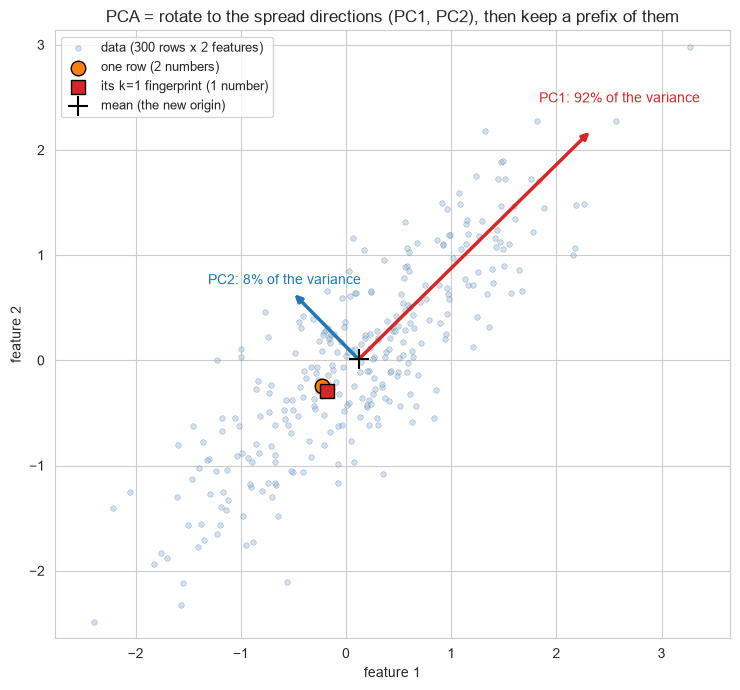

explained variance ratios: PC1 92.3%, PC2 7.7%
keeping everything (k=2): reconstruction is exact (max |X - reconstructed| = 8.9e-16) — a pure rotation

💡 PCA did not select or drop features: it ROTATED the plane until one axis held the story.
   Keeping only PC1 stores 1 number per row and keeps 92% of the spread;
   the dotted segment is exactly the spread that got thrown away.


In [2]:
# A correlated 2-D cloud: two features telling largely one story
rng_vis = np.random.default_rng(7)
cov2 = np.array([[1.0, 0.85],
                 [0.85, 1.0]])
X2 = rng_vis.multivariate_normal(np.zeros(2), cov2, size=300)

pca2_full = PCAScratch(n_components=2).fit(X2)
pca2_k1 = PCAScratch(n_components=1).fit(X2)
X2_hat1 = pca2_k1.inverse_transform(pca2_k1.transform(X2))   # k = 1 reconstruction

fig, ax = plt.subplots(figsize=(7.5, 7.0))
ax.scatter(X2[:, 0], X2[:, 1], s=16, alpha=0.5, color="#9ec5e8",
           edgecolors="k", linewidths=0.2, label="data (300 rows x 2 features)")
for i, (lam, v) in enumerate(zip(pca2_full.explained_variance_, pca2_full.components_), start=1):
    color = "#d62728" if i == 1 else "#1f77b4"
    ax.annotate("", xy=pca2_full.mean_ + 2.5 * np.sqrt(lam) * v, xytext=pca2_full.mean_,
                arrowprops=dict(arrowstyle="-|>", color=color, lw=2.5))
    ax.text(*(pca2_full.mean_ + 2.8 * np.sqrt(lam) * v),
            f"PC{i}: {pca2_full.explained_variance_ratio_[i - 1]:.0%} of the variance",
            color=color, fontsize=10, ha="center")

marker = X2[240]
ax.scatter(*marker, color="#ff7f0e", s=110, edgecolors="k", zorder=6, label="one row (2 numbers)")
ax.scatter(*X2_hat1[240], color="#d62728", marker="s", s=110, edgecolors="k", zorder=6,
           label="its k=1 fingerprint (1 number)")
ax.plot([marker[0], X2_hat1[240][0]], [marker[1], X2_hat1[240][1]],
        color="gray", ls=":", lw=1.4, zorder=5)
ax.scatter(*pca2_full.mean_, marker="+", s=220, color="black", zorder=6, label="mean (the new origin)")

ax.set_title("PCA = rotate to the spread directions (PC1, PC2), then keep a prefix of them")
ax.set_xlabel("feature 1")
ax.set_ylabel("feature 2")
ax.axis("equal")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

ratio1 = pca2_full.explained_variance_ratio_[0]
print(f"explained variance ratios: PC1 {pca2_full.explained_variance_ratio_[0]:.1%}, "
      f"PC2 {pca2_full.explained_variance_ratio_[1]:.1%}")
kept_exact = pca2_full.inverse_transform(pca2_full.transform(X2))
print(f"keeping everything (k=2): reconstruction is exact "
      f"(max |X - reconstructed| = {np.max(np.abs(X2 - kept_exact)):.1e}) — a pure rotation")
print(f"\n💡 PCA did not select or drop features: it ROTATED the plane until one axis held the story.")
print(f"   Keeping only PC1 stores 1 number per row and keeps {ratio1:.0%} of the spread;")
print("   the dotted segment is exactly the spread that got thrown away.")

---

## 2. Theory & Mathematics

### Core Concept: Variance Along One Direction

Work with the centered data matrix $X_c = X - \bar{x}$ ($n$ rows, $d$ features; both the twin and scikit-learn center before anything else). Pick a unit direction $v \in \mathbb{R}^d$. Projecting every row onto it gives coordinates $z = X_c v$, and the information in that direction is the sample variance of those coordinates:

$$\mathrm{Var}(X_c v) \;=\; v^\top \Sigma\, v, \qquad \Sigma = \frac{1}{n-1} X_c^\top X_c \quad (\text{ddof}=1)$$

PCA asks: which $v$ maximizes this? Maximizing $v^\top \Sigma v$ over unit $v$ (a Lagrange-multiplier problem) gives the eigenproblem

$$\Sigma v = \lambda v$$

The **eigenvectors of the covariance matrix are the principal directions**, and each **eigenvalue is the variance along its eigenvector**. Sorting the eigenpairs descending gives the principal components: component $i$ is a unit vector $v_i$, the $i$-th row of the `components_` attribute, and its variance $\lambda_i$ is `explained_variance_[i]`.

### What PCA Actually Computes

- **`explained_variance_ratio_[i]`**: the share of the TOTAL spread that component $i$ carries, $\lambda_i \big/ \sum_j \lambda_j$. The denominator is the trace of $\Sigma$ — the summed variance of the original features — a property of the **dataset**, independent of how many components you keep
- **The transform**: $Z = X_c W$ with $W$ = the kept rows of `components_` (k × d). Every row of $X$ becomes k coordinates
- **The reconstruction**: $\hat{X} = Z W + \bar{x}$. By the Eckart–Young theorem this is the **best possible rank-k rendering** of the data: no other k-dimensional plane reproduces less squared spread. The leftover error is the sum of the dropped eigenvalues — known before fitting, not learned (§7)
- **Full rank is exact**: keep $k = \mathrm{rank}(X_c)$ and the reconstruction reproduces the input to float precision. Compression loses ONLY the smallest eigenvalues

### Orthogonality: A Rotation, Not a Selection

$\Sigma$ is symmetric positive-semidefinite, so its eigenvectors are orthonormal ($W W^\top = I$) and its eigenvalues are real and non-negative. Consequences worth internalizing:

- **`transform` decorrelates by construction**: the kept coordinates are mutually uncorrelated — pairs of $Z$ columns have near-zero linear correlation even when the raw features were tightly coupled. Downstream linear models stop paying the multicollinearity price
- **Nothing is dropped by fitting**: fitting resolves the whole spectrum at once. `n_components` only chooses how many of the already-computed axes to keep (§8)
- **The components are NOT the original features**: each PC is a linear combination of all of them. Loadings can be read (§10 Example 1), but a large coefficient does not make a PC "be" that feature

### Uniqueness up to Sign

$(v, \lambda)$ and $(-v, \lambda)$ solve the eigenproblem equally well — an axis is a direction, not an arrow. Both engines fix a convention per row (the largest-absolute loading positive, §5), so loadings are comparable across engines; however genuine ties (repeated eigenvalues) leave the direction itself rotation-arbitrary inside its eigenspace, for both engines alike.

In [3]:
# Theory in numbers: verify the eigen-property on a small 2-D sample
rng_t = np.random.default_rng(3)
X_t = rng_t.multivariate_normal([0.0, 0.0], np.array([[3.0, 2.1], [2.1, 3.0]]), size=500)
Sigma_t = np.cov(X_t, rowvar=False)                # ddof=1 sample covariance — the twin's estimator

evals_t, evecs_t = np.linalg.eigh(Sigma_t)         # eigh: ascending order, exact, deterministic
v1_t = evecs_t[:, -1]                              # leading eigenvector (largest eigenvalue)
lam1_t = float(evals_t[-1])

proj_t = (X_t - X_t.mean(axis=0)) @ v1_t           # coordinates of every row along v1
var_proj_t = float(np.var(proj_t, ddof=1))         # sample variance of those coordinates

print(f"Sigma (ddof=1 covariance) =\n{np.round(Sigma_t, 3)}")
print(f"\nleading eigenvalue  lambda_1              = {lam1_t:.4f}")
print(f"sample variance of projections onto v1    = {var_proj_t:.4f}   <- equal, as the theory says")
print(f"Sigma @ v1 = {np.round(Sigma_t @ v1_t, 4)}")
print(f"lambda_1 * v1 = {np.round(lam1_t * v1_t, 4)}   <- equal, the eigenproblem Sigma v = lambda v")
print(f"v1 . v2 = {float(v1_t @ evecs_t[:, 0]):.1e}   <- the two eigenvectors are orthogonal")

total_var_t = float(np.trace(Sigma_t))
print(f"\ntrace(Sigma) = total variance across both features = {total_var_t:.4f}")
print(f"lambda_1 share = lambda_1 / trace = {lam1_t / total_var_t:.1%} of the total spread")
print("\n💡 The eigen-decomposition IS the PCA: directions of pure spread, one eigenvalue of variance each.")
print("   Every attribute the twin and sklearn expose is bookkeeping on top of these two arrays.")

Sigma (ddof=1 covariance) =
[[3.092 2.094]
 [2.094 2.947]]

leading eigenvalue  lambda_1              = 5.1148
sample variance of projections onto v1    = 5.1148   <- equal, as the theory says
Sigma @ v1 = [-3.6789 -3.5535]
lambda_1 * v1 = [-3.6789 -3.5535]   <- equal, the eigenproblem Sigma v = lambda v
v1 . v2 = 0.0e+00   <- the two eigenvectors are orthogonal

trace(Sigma) = total variance across both features = 6.0388
lambda_1 share = lambda_1 / trace = 84.7% of the total spread

💡 The eigen-decomposition IS the PCA: directions of pure spread, one eigenvalue of variance each.
   Every attribute the twin and sklearn expose is bookkeeping on top of these two arrays.


### The SVD Connection and the Cost Table

scikit-learn factorizes the **centered data** with the SVD instead of decomposing the covariance; the twin decomposes the **covariance** with `eigh`. For one symmetric matrix built from the same centered data the two roads return the same eigensystem:

$$X_c = U S V^\top \quad \Longrightarrow \quad \Sigma = \tfrac{1}{n-1} V S^2 V^\top$$

so the two engines relate attribute by attribute:

| sklearn attribute | SVD object | Twin's object (covariance path) |
|---|---|---|
| `components_` | $V^\top$ rows | leading eigenvectors, transposed to rows |
| `singular_values_` | $s_i$ (the 2-norm of each component's coordinates) | $\sqrt{(n-1)\,\lambda_i}$ — not kept by the twin |
| `explained_variance_` | $s_i^2 / (n-1)$ | eigenvalue $\lambda_i$ |
| `explained_variance_ratio_` | $s_i^2 / \sum_j s_j^2$ | $\lambda_i / \mathrm{trace}(\Sigma)$ |

`noise_variance_` — average of the smallest $\min(n, d) - k$ eigenvalues — is the Probabilistic-PCA noise estimate (Tipping & Bishop). The twin does not expose it; §6 inspects it via sklearn.

**Computational cost** (n samples, d features, k kept):

| Path | Cost | Used by |
|---|---|---|
| Covariance + `eigh` | $O(nd^2 + d^3)$ | the twin; sklearn's `covariance_eigh` solver |
| Full exact SVD | $O(nd^2 + d^3)$ | sklearn's `full` solver |
| Randomized truncated SVD | $O(ndk)$ | sklearn's `randomized` solver; wins for big n |

For $n \gg d$ (wide-spectrum sensors, images flattened, our 240 × 4 dataset) the covariance path is the cheapest exact road — which is why scikit-learn's `auto` policy picks `covariance_eigh` exactly there (§6).

In [4]:
# Cross-checks #1 and #2: the SVD identity, then a rank-deficient dataset
U_t, S_t, Vt_t = np.linalg.svd(X_t - X_t.mean(axis=0), full_matrices=False)   # singular values: descending
var_from_svd_t = (S_t ** 2) / (len(X_t) - 1)

print(f"eigenvalues (descending)      : {np.round(evals_t[::-1], 4)}")
print(f"S^2/(n-1) from the SVD        : {np.round(var_from_svd_t, 4)}")
print(f"singular values sqrt((n-1)λ)  : {np.round(np.sqrt((len(X_t) - 1) * evals_t[::-1]), 3)}")


def align_rows(A, B):
    # Flip each row of A so it points the same way as B's matching row
    return A * np.sign((A * B).sum(axis=1, keepdims=True))


twin_t = PCAScratch(n_components=2).fit(X_t)
components_match = np.allclose(align_rows(twin_t.components_, Vt_t), Vt_t, atol=1e-10)
print(f"\ntwin components_ == V^T (up to sign): {components_match}")
print(f"ratios sum to 1 when k is full      : {float(twin_t.explained_variance_ratio_.sum()):.12f}")

# Rank-deficient data: duplicate feature 1 onto feature 0 -> rank 1 of 2, one eigenvalue collapses to ~0
X2_dup = X2.copy()
X2_dup[:, 0] = X2_dup[:, 1]
twin_dup = PCAScratch(n_components=2).fit(X2_dup)
vanished = float(twin_dup.explained_variance_ratio_[-1])
print(f"\nduplicated-feature cloud, last component ratio: {vanished:.2e}   (~0: rank 1 in 2 dims)")
print("\n💡 V, the right singular vectors of the centered data, IS the principal-component basis.")
print("   And a duplicated feature is not 'extra information' — its eigenvalue collapses to zero")
print("   (the twin clamps the ~1e-16 numerical residue to exactly that).")

eigenvalues (descending)      : [5.1148 0.9239]
S^2/(n-1) from the SVD        : [5.1148 0.9239]
singular values sqrt((n-1)λ)  : [50.52  21.472]

twin components_ == V^T (up to sign): True
ratios sum to 1 when k is full      : 1.000000000000

duplicated-feature cloud, last component ratio: 0.00e+00   (~0: rank 1 in 2 dims)

💡 V, the right singular vectors of the centered data, IS the principal-component basis.
   And a duplicated feature is not 'extra information' — its eigenvalue collapses to zero
   (the twin clamps the ~1e-16 numerical residue to exactly that).


### Why Scaling Is Not Optional

$\Sigma$'s diagonal IS the per-feature variance **in raw feature units**, and PCA orders directions by that currency. A feature measured in thousands inflates the total variance a thousandfold. Three practical traps follow:

1. **Wide-range features hijack the spectrum**. One column in "currency" units next to columns in "fractions" makes PC1 point almost exactly along the wide-range feature — the correlation structure becomes invisible, and every ratio line becomes a statement about units, not data
2. **Comparable units still carry equal votes**. If features are already on comparable scales, standardizing changes nothing (variances are already ~equal); it is neither wrong nor needed
3. **Standardization re-weights the goal**. On standardized features, $\Sigma$ becomes the correlation matrix: PCA then ranks directions purely by how tightly features move together — the "pure correlation structure" view. The Kaiser rule (keep components with $\lambda > 1$, i.e. more variance than one standardized feature) only means anything there

Both engines center but do **not** scale. If your features do not share units, standardize first — inside a Pipeline, fitted on training rows only (§6, §9). If they do share units and those units are meaningful (pixels 0–255, spectral absorbance), PCA can be fit on the raw values.

             fit feature stds (rounded) PC1 |loading| at its top feature PC1 variance share
   raw (std ~ 1)    0.95-0.97-1.01-0.94                    feat 2: 0.546             75.49%
    standardized    1.00-1.00-1.00-1.00                    feat 1: 0.544             75.05%
feature 3 x 1000      1.0-1.0-1.0-944.2                    feat 3: 1.000            100.00%


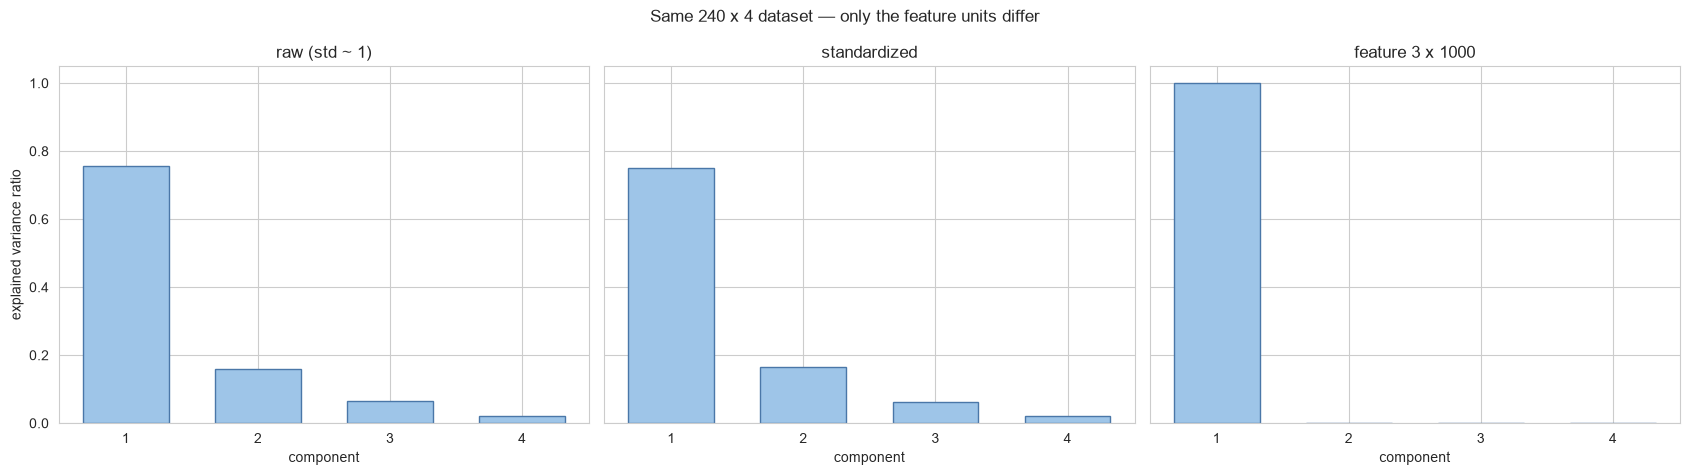

raw vs standardized: max ratio gap = 0.007   (small — these features were born with
   comparable stds around 1, so standardizing barely re-weights anything; the x1000 row above
   is what unit mismatch does instead)

💡 Scaling is only about UNITS. Comparable features need none; mismatched units make PC1 a
   unit-conversion statement (here 100% of the variance
   collapses onto feature 3). Standardize inside the Pipeline when units disagree.


In [5]:
# The app's dataset: four correlated features on comparable scales (240 rows, same data the Streamlit
# app's PCA card fits — 'pca_correlated_4f' in app/core/datasets.py)
rng_main = np.random.default_rng(0)
cov4 = np.array([[1.0, 0.9, 0.7, 0.4],
                 [0.9, 1.0, 0.8, 0.5],
                 [0.7, 0.8, 1.0, 0.6],
                 [0.4, 0.5, 0.6, 1.0]])
X4 = rng_main.multivariate_normal(np.zeros(4), cov4, size=240)

pca_raw = PCAScratch(n_components=4).fit(X4)                 # raw features (std ~ 1 each)
X4_std = StandardScaler().fit_transform(X4)
pca_std = PCAScratch(n_components=4).fit(X4_std)             # standardized

# One feature switched to 'currency' units (x1000): a trap in action
X4_big = X4.copy()
X4_big[:, 3] *= 1000.0
pca_big = PCAScratch(n_components=4).fit(X4_big)

# The hijack check: which feature owns PC1's largest loading, for each fit?
lead_raw = int(np.argmax(np.abs(pca_raw.components_[0])))
lead_std = int(np.argmax(np.abs(pca_std.components_[0])))
lead_big = int(np.argmax(np.abs(pca_big.components_[0])))

rows_scale = pd.DataFrame(
    {
        "fit": ["raw (std ~ 1)", "standardized", "feature 3 x 1000"],
        "feature stds (rounded)": ["-".join(f"{s:.2f}" for s in X4.std(axis=0)),
                                   "1.00-1.00-1.00-1.00",
                                   "-".join(f"{s:.1f}" for s in X4_big.std(axis=0))],
        "PC1 |loading| at its top feature": [f"feat {lead_raw}: {abs(pca_raw.components_[0][lead_raw]):.3f}",
                                             f"feat {lead_std}: {abs(pca_std.components_[0][lead_std]):.3f}",
                                             f"feat {lead_big}: {abs(pca_big.components_[0][lead_big]):.3f}"],
        "PC1 variance share": [f"{pca_raw.explained_variance_ratio_[0]:.2%}",
                               f"{pca_std.explained_variance_ratio_[0]:.2%}",
                               f"{pca_big.explained_variance_ratio_[0]:.2%}"],
    }
)
print(rows_scale.to_string(index=False))

fig, axes = plt.subplots(1, 3, figsize=(17, 4.8), sharey=True)
for ax_fit, (label, model) in zip(axes, [("raw (std ~ 1)", pca_raw),
                                         ("standardized", pca_std),
                                         ("feature 3 x 1000", pca_big)]):
    ax_fit.bar(np.arange(1, 5), model.explained_variance_ratio_, color="#9ec5e8",
               edgecolor="#4a77a8", width=0.65)
    ax_fit.set_xticks(np.arange(1, 5))
    ax_fit.set_title(label)
    ax_fit.set_xlabel("component")
axes[0].set_ylabel("explained variance ratio")
fig.suptitle("Same 240 x 4 dataset — only the feature units differ")
plt.tight_layout()
plt.show()

gap_raw_std = np.max(np.abs(pca_raw.explained_variance_ratio_ - pca_std.explained_variance_ratio_))
print(f"raw vs standardized: max ratio gap = {gap_raw_std:.3f}   (small — these features were born with")
print("   comparable stds around 1, so standardizing barely re-weights anything; the x1000 row above")
print("   is what unit mismatch does instead)")
print("\n💡 Scaling is only about UNITS. Comparable features need none; mismatched units make PC1 a")
print(f"   unit-conversion statement (here {pca_big.explained_variance_ratio_[0]:.0%} of the variance")
print("   collapses onto feature 3). Standardize inside the Pipeline when units disagree.")

---

## 3. Assumptions & Requirements

PCA has **no distributional model** to violate — it is deterministic linear algebra on any matrix. What can be violated is whether its **interpretation** holds: that the output directions mean anything, and that keeping the top of the variance ranking keeps the information you care about.

### Critical Assumptions

#### ✅ 1. **Linear Structure**
- Each PC is a fixed linear combination of all features; curved manifolds (the rings and moons geometries of notebooks 12/13) get flattened or smeared by a straight plane
- **Test**: look at the 2–3-component projection; check the reconstruction error at the k you plan to keep (§7)
- **Fix**: `KernelPCA` (§6), UMAP/t-SNE for pure visualization, or nonlinear feature engineering first

#### ✅ 2. **Variance = Importance**
- PCA orders by spread and is blind to any supervising target. High-variance noise survives its cut; low-variance but predictive features do not (§11 demonstrates a case where the top components are pure noise)
- **Test**: downstream cross-validated score with PCA in the pipeline vs without (§7)
- **Fix**: choose k by downstream CV, or use a supervised reducer (`LDA`, `SelectKBest`)

#### ✅ 3. **Comparable Feature Scales**
- Variance is measured in raw units; unscaled features of different magnitudes make the spectrum a units statement (§2 demo)
- **Test**: per-feature standard deviations; PC1's loading pattern
- **Fix**: `StandardScaler` inside the pipeline, fitted on training rows only

#### ✅ 4. **Continuous Numeric Features**
- PCA needs arithmetic on features. One-hot columns produce odd "membership-set" components (personas, not axes); the practice is workable but rarely what you wanted
- **Fix**: keep categoricals out and reduce only the numeric block, use MCA-style methods, or accept mixture components knowingly

#### ✅ 5. **Outlier Tolerance**
- Means and covariances are not robust: a single extreme row drags both. The principal axis can swing visibly for one bad row (demo below)
- **Test**: scatter plots; refit with and without suspicious rows
- **Fix**: cap/remove outliers first; robust scalers; or robust covariance variants outside this notebook's scope

#### ✅ 6. **Complete Data**
- Both engines require finite floats; `NaN`/`inf` raise at fit time
- **Fix**: impute inside the pipeline BEFORE the scaler

### When Assumptions Are Violated

| Violation | Symptom | Fix |
|---|---|---|
| Nonlinear structure | Poor reconstruction even at moderate k; 2-D projection smears clusters | `KernelPCA`, t-SNE/UMAP for visualization |
| Variance ≠ signal | Downstream accuracy drops after PCA | k by downstream CV; LDA / SelectKBest |
| Unscaled features | PC1 ≈ one wide-range feature; ratios track units | Standardize in-pipeline |
| One-hot block inside the matrix | Persona-like components; unstable loadings | Reduce the numeric block only; MCA |
| Outliers in the data | One component pivots to chase extreme rows | Cap/clean; robust alternatives |
| NaN in the matrix | ValueError at fit | Impute before the pipeline |

### Data Requirements

- **Shape**: at least 2 rows (ddof=1 needs it); the sample covariance is full-rank up to $\min(n-1, d)$ dimensions — with $n \le d$ you get zero-variance directions, which is fine but keeps no compression potential beyond $\mathrm{rank}$
- **Sample size for a stable spectrum**: an order of magnitude more rows than features keeps ratios steady under resampling; a 20 × 200 matrix's "spectrum" is mostly noise
- **Scaling decision made explicitly** (§2)
- **Encoding decision made explicitly** (categoricals in or out)
- **No missing values**

> **The demo that follows** shows the outlier assumption in action: the same cloud fitted with and without one extreme row.

PC1 angle without the outlier: +44.6 deg
PC1 angle with one outlier   : +43.7 deg   (1 row out of 201)
the axis moved 0.9 degrees because of a single point


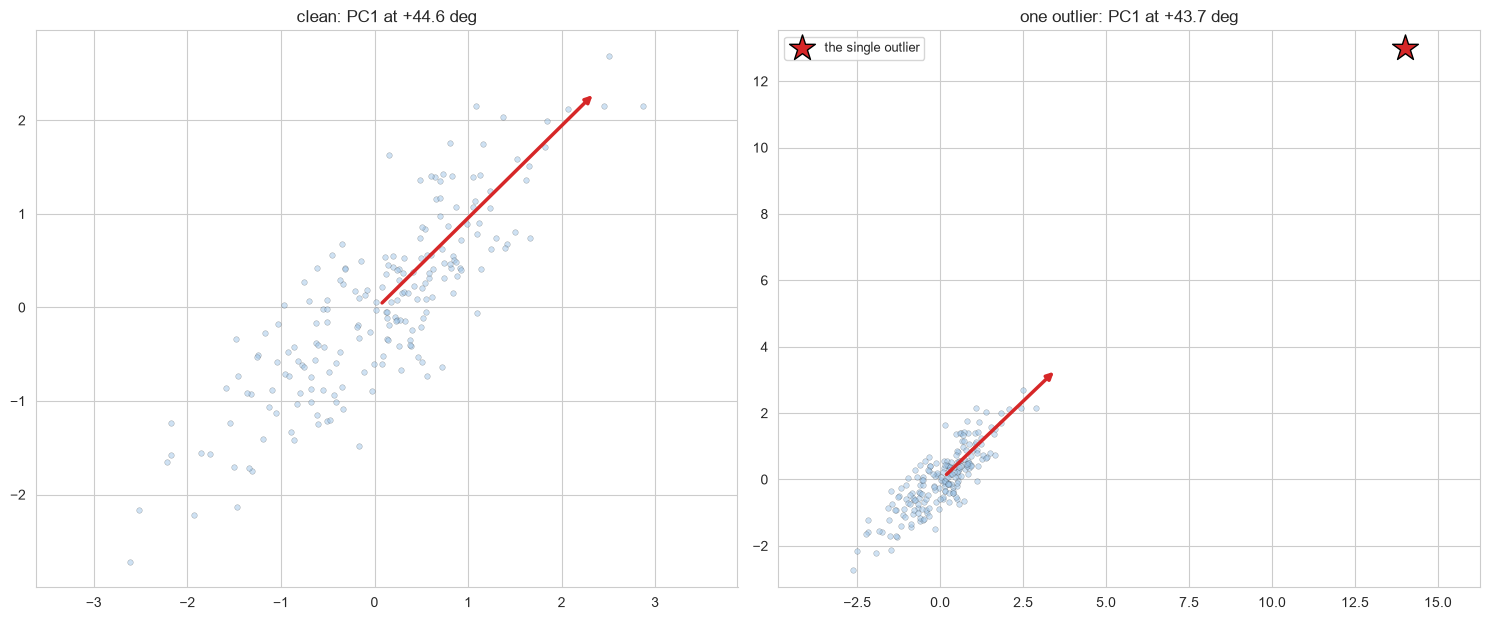


💡 Means and covariances summarize with every row weighted equally — including the extreme ones.
   A single bad row can redirect an axis that should describe the other 200. Screen outliers
   BEFORE trusting loadings: the summary statistics are exactly what the axis is built from.


In [6]:
# One outlier out of 201 rows pivots the principal axis
rng_out = np.random.default_rng(5)
X2_out_base = rng_out.multivariate_normal(np.zeros(2), cov2, size=200)
X2_outlier = np.vstack([X2_out_base, [[14.0, 13.0]]])

pca_clean = PCAScratch(n_components=2).fit(X2_out_base)
pca_pivot = PCAScratch(n_components=2).fit(X2_outlier)


def pc_angle(v):
    return float(np.degrees(np.arctan2(v[1], v[0])))


angle_clean, angle_pivot = pc_angle(pca_clean.components_[0]), pc_angle(pca_pivot.components_[0])
print(f"PC1 angle without the outlier: {angle_clean:+.1f} deg")
print(f"PC1 angle with one outlier   : {angle_pivot:+.1f} deg   (1 row out of {len(X2_outlier)})")
print(f"the axis moved {abs(angle_pivot - angle_clean):.1f} degrees because of a single point")

fig, axes = plt.subplots(1, 2, figsize=(15, 6.3))
for ax_pay, (data, model, trojan_row, title) in zip(axes, [
        (X2_out_base, pca_clean, None, f"clean: PC1 at {angle_clean:+.1f} deg"),
        (X2_outlier, pca_pivot, [14.0, 13.0], f"one outlier: PC1 at {angle_pivot:+.1f} deg")]):
    ax_pay.scatter(data[:, 0], data[:, 1], s=16, alpha=0.5, color="#9ec5e8",
                   edgecolors="k", linewidths=0.2)
    lam1 = model.explained_variance_[0]
    v1 = model.components_[0]
    ax_pay.annotate("", xy=model.mean_ + 2.5 * np.sqrt(lam1) * v1, xytext=model.mean_,
                    arrowprops=dict(arrowstyle="-|>", color="#d62728", lw=2.5))
    if trojan_row is not None:
        ax_pay.scatter(*trojan_row, color="#d62728", marker="*", s=380, edgecolors="k",
                       zorder=6, label="the single outlier")
        ax_pay.legend(fontsize=9, loc="upper left")
    ax_pay.axis("equal")
    ax_pay.set_title(title)
plt.tight_layout()
plt.show()

print("\n💡 Means and covariances summarize with every row weighted equally — including the extreme ones.")
print("   A single bad row can redirect an axis that should describe the other 200. Screen outliers")
print("   BEFORE trusting loadings: the summary statistics are exactly what the axis is built from.")

---

## 4. When to Use This Algorithm

### ✅ Use PCA When:

1. **Features are numeric, correlated, and you can accept mixture columns**
   - Compression with a known error budget: drop the smallest eigenvalues, keep the spread
   - The companion dataset keeps roughly two-thirds of 4 features' spread in 1 component — a real reduction, not just a reshuffle
2. **Downstream models suffer from multicollinearity or dimensionality**
   - Decorrelated inputs stabilize linear/logistic regression; fewer coordinates speed up KNN and SVM
   - k-by-CV inside a pipeline is the mechanism (§7)
3. **You need a 2–3-D view of high-dimensional data**
   - The fastest honest map of structure; §10 Example 2 projects 64-D digits onto 2
4. **You need to denoise or smooth**
   - The small-eigenvalue tail is typically noise; projecting onto the top components and reconstructing removes it (§10 Example 2 part C)
5. **You want determinism and speed**
   - No seeds, no iterations, one eigendecomposition; a 240 × 4 fit is microseconds, and results are reproducible bit-for-bit
6. **Unsupervised preprocessing must not leak the target**
   - PCA never sees `y`, so using it inside CV pipelines cannot smuggle label information... as long as it is fit on training rows only (§9)

### ❌ Avoid PCA When:

1. **Named-feature interpretability is the product**
   - Components are mixtures of everything; coefficients are loadings, not effects. Reach for selection or regularized models instead
2. **Variance does not track the target**
   - Supervised tasks with narrow-but-predictive features: `LDA`/`SelectKBest` respects the label, PCA does not (§11)
3. **Strong nonlinear structure dominates**
   - Straight planes cannot follow curved manifolds: `KernelPCA`, or visualization-only t-SNE/UMAP
4. **Categorical features are the bulk of the matrix**
   - One-hot blocks make persona components, not axes; MCA-style techniques are the honest tool
5. **Streaming/very large data with strict memory**
   - Exact covariance costs O(d²) memory and needs all rows: `IncrementalPCA`/randomized solvers (§6, §8)

### Real-world Applications

- **Eigenfaces / face recognition**: compressing pixel blocks onto a small component basis (the historical classic)
- **Genomics and biomedicine**: batch effects, population structure, and feature preprocessing before classifiers
- **Industrial monitoring / sensor fusion**: compress arrays of correlated sensors into a few health indices
- **Image compression**: eigenvalue truncation as an error-bounded compression (§10 Example 2's reconstruction gallery)
- **Finance**: factor extraction from correlated asset/price panels

### Registry Entry (how the Streamlit app treats PCA)

The app card (`app/registry/algorithms/pca.py`) declares PCA as a **transform** card on the `pca_correlated_4f` dataset, with `n_components` as its one slider and "cumulative explained variance" as its metric — the same dataset this notebook fitted in §2 and will re-fit all through §5–§6.

### PCA vs the Sibling Transformers (preview of §11)

- **vs K-Means / hierarchical clustering (12, 13)**: clustering groups ROWS; PCA re-describes COLUMNS. They compose freely — notebook 12 used a quick 2-component PCA peek of its own data, and clustering on PCA coordinates is a common pattern
- **vs feature selection (`SelectKBest`, LDA)**: selection keeps original features and can read the label; PCA invents mixture features and cannot. Variance-based reduction is labeling-blind — which is either the safety property (no leakage) or the failure mode (signal dropped), depending on the task (§11 demonstrates both sides)
- **vs TruncatedSVD**: same rotation machinery without centering; matters for sparse matrices and for data with a large mean shift (§11 demo)
- **vs neural autoencoders (17's nonlinear cousins)**: powerful nonlinear compression, at the cost of seeds, hyperparameters, and training time; PCA is the deterministic zero-knob baseline they must beat

---

## 5. Implementation from Scratch (NumPy)

### Why Implement PCA from Scratch?

- The eigendecomposition looks like one NumPy call — until ordering, numerical clamping, the sign of every eigenvector, and the meaning of `transform`/`inverse_transform` all have to be handled explicitly
- The fitted attributes become physical objects you can print and inspect: axes (rows with d coefficients), variances (eigenvalues), shares of the total (ratios), and the fitted center
- It exposes the edge cases scikit-learn hides: rank-deficient data with ~1e-16 eigenvalues of either sign, why a single sample is not fittable, and why `n_components` is validated at fit time

The from-scratch twin lives in `src/models/dimensionality_reduction.py` as **`PCAScratch`**. It fits the exact ddof=1 covariance eigendecomposition once and in full; the k kept components are only sliced out afterwards. It mirrors scikit-learn's attribute names (`components_`, `explained_variance_`, `explained_variance_ratio_`, `mean_`, `n_components_`) so the same calling code fits either engine.

What is deliberately simplified (documented in the module):

- **One code path**: eigendecomposition of the sample covariance. scikit-learn factorizes the centered data with the SVD; the components and variances agree to float precision for n ≥ 2, but the two are not bit-identical algorithms
- **Negative clamping**: numerically rank-deficient data yields ~1e-16 eigenvalues of either sign; the twin clamps them to 0, like sklearn's covariance-eigendecomposition solver (its SVD path cannot produce negatives by construction)
- **A fixed sign convention**: each kept axis gets its largest-absolute loading made positive, so scratch and sklearn loadings are directly comparable (genuine ties on that coefficient leave the sign data-dependent — same as sklearn's `svd_flip`)
- **No whiten, `svd_solver`, `tol`, or randomized-solver knobs**: the exact decomposition needs none of them
- **Minimal validation surface**: dtypes are cast to float64 and shape / `n_components` are checked in fit only; a single-sample X raises there (ddof=1 needs ≥ 2 rows), and transform/inverse rely on NumPy raising for feature-count mismatches

In [7]:
print("✅ Available class: PCAScratch (src/models/dimensionality_reduction.py)")
print("\nAPI (mirrors scikit-learn's PCA names where they matter):")
print("  • PCAScratch(n_components=None)     # an int, or None = keep min(n_samples, n_features)")
print("  • .fit(X)                  # centers rows, eigendecomposes the ddof=1 covariance, keeps k")
print("  • .transform(X) -> (n, k)  # centered rows projected onto the kept axes")
print("  • .fit_transform(X)        # fit + transform of the same rows")
print("  • .inverse_transform(X)    # coordinates mapped back to feature space")
print("\nFitted attributes (same names as sklearn, by design):")
print("  • components_                 (k, n_features) — unit rows, sign-normalized")
print("  • explained_variance_         (k,)            — the leading eigenvalues λ")
print("  • explained_variance_ratio_   (k,)            — λ as shares of the TOTAL variance")
print("  • mean_                       (n_features,)   — per-feature training mean")
print("  • n_components_               int             — resolved k")

✅ Available class: PCAScratch (src/models/dimensionality_reduction.py)

API (mirrors scikit-learn's PCA names where they matter):
  • PCAScratch(n_components=None)     # an int, or None = keep min(n_samples, n_features)
  • .fit(X)                  # centers rows, eigendecomposes the ddof=1 covariance, keeps k
  • .transform(X) -> (n, k)  # centered rows projected onto the kept axes
  • .fit_transform(X)        # fit + transform of the same rows
  • .inverse_transform(X)    # coordinates mapped back to feature space

Fitted attributes (same names as sklearn, by design):
  • components_                 (k, n_features) — unit rows, sign-normalized
  • explained_variance_         (k,)            — the leading eigenvalues λ
  • explained_variance_ratio_   (k,)            — λ as shares of the TOTAL variance
  • mean_                       (n_features,)   — per-feature training mean
  • n_components_               int             — resolved k


### Fit and Inspect: the Companion Dataset

`X4` is the dataset the Streamlit app's PCA card fits (`pca_correlated_4f`, §2): 240 rows, 4 correlated features on comparable scales. Every claim below can be checked against the app's **Metrics row** after the demo runs. There is no train/test split and no `y` here — compression of a known dataset is the product — and section 6 will fit the very same arrays with scikit-learn to check engine agreement.

In [8]:
print("=" * 60)
print("PCA (FROM SCRATCH) ON THE APP'S CORRELATED DATASET")
print("=" * 60)
print(f"\n📊 Dataset: {X4.shape[0]} rows x {X4.shape[1]} correlated features")

pca_s = PCAScratch().fit(X4)          # n_components=None keeps all min(240, 4) = 4 components

print("\n🌀 Fitted spectrum:")
cum_s = 0.0
for i in range(pca_s.n_components_):
    cum_s += pca_s.explained_variance_ratio_[i]
    print(f"  PC{i + 1}: λ = {pca_s.explained_variance_[i]:7.4f}   "
          f"ratio = {pca_s.explained_variance_ratio_[i]:6.2%}   cumulative = {cum_s:6.2%}")

W_s = pca_s.components_
unit_ok = np.allclose(W_s @ W_s.T, np.eye(W_s.shape[0]), atol=1e-10)
lead_idx = np.argmax(np.abs(W_s), axis=1)
sign_ok = bool(np.all(W_s[np.arange(len(W_s)), lead_idx] > 0))
print(f"\n🔍 Health checks:")
print(f"  W Wᵀ = I (orthonormal axes):              {unit_ok}")
print(f"  every axis' largest-|loading| positive:   {sign_ok}")
print(f"  mean_ equals X4.mean(axis=0):             {np.allclose(pca_s.mean_, X4.mean(axis=0))}")
print(f"  transform shape for k=4:                  {pca_s.transform(X4).shape}")

# The reconstruction bookkeeping, in numbers
Xhat_full_s = pca_s.inverse_transform(pca_s.transform(X4))
exactness = float(np.max(np.abs(X4 - Xhat_full_s)))

pca_s1 = PCAScratch(n_components=1).fit(X4)
Z1_s = pca_s1.fit_transform(X4)
Xhat1_s = pca_s1.inverse_transform(Z1_s)
err_plain = float(((X4 - Xhat1_s) ** 2).sum(axis=1).mean())            # plain per-row mean
dropped_lam = float(pca_s.explained_variance_[1:].sum())
expected_plain = dropped_lam * (len(X4) - 1) / len(X4)                 # eigenvalues use ddof=1

print(f"\n🧮 The compression accountant:")
print(f"  k=4 reconstruction max |X - X̂| = {exactness:.1e}   (exact — keeping rank dims loses nothing)")
print(f"  k=1: plain-mean squared reconstruction error = {err_plain:.4f}")
print(f"  sum of the 3 dropped eigenvalues × (n-1)/n    = {expected_plain:.4f}   <- equal (Eckart–Young)")
print("\n💡 The error was a sum in a table before any reconstruction was computed: compression loses")
print("   exactly the dropped eigenvalues, and nothing else. The (n-1)/n factor is the ddof=1")
print("   convention of the covariance estimator, not a new assumption.")

PCA (FROM SCRATCH) ON THE APP'S CORRELATED DATASET

📊 Dataset: 240 rows x 4 correlated features

🌀 Fitted spectrum:
  PC1: λ =  2.8430   ratio = 75.49%   cumulative = 75.49%
  PC2: λ =  0.5976   ratio = 15.87%   cumulative = 91.36%
  PC3: λ =  0.2431   ratio =  6.46%   cumulative = 97.82%
  PC4: λ =  0.0822   ratio =  2.18%   cumulative = 100.00%

🔍 Health checks:
  W Wᵀ = I (orthonormal axes):              True
  every axis' largest-|loading| positive:   True
  mean_ equals X4.mean(axis=0):             True
  transform shape for k=4:                  (240, 4)

🧮 The compression accountant:
  k=4 reconstruction max |X - X̂| = 2.7e-15   (exact — keeping rank dims loses nothing)
  k=1: plain-mean squared reconstruction error = 0.9190
  sum of the 3 dropped eigenvalues × (n-1)/n    = 0.9190   <- equal (Eckart–Young)

💡 The error was a sum in a table before any reconstruction was computed: compression loses
   exactly the dropped eigenvalues, and nothing else. The (n-1)/n factor is the ddo

### How the Scratch Version Works (a guided tour)

Read `src/models/dimensionality_reduction.py` alongside these facts:

**1. Everything numerical happens once, inside `fit` (lines ~71–128).**
The rows are cast to float64, centered by their column means, and passed to `np.cov(X_centered, rowvar=False)` — the ddof=1 sample covariance. Then one call: `np.linalg.eigh(covariance)`.

**2. `eigh` returns eigenvalues in ASCENDING order — the twin reverses them.**
`eigh` is the exact, deterministic solver for symmetric matrices: no iterations, no convergence criterion, no `random_state` anywhere. The reversal turns the ascending list into the descending "principal" order.

**3. `n_components` is resolved and validated at fit time.**
`None` resolves to `min(n_samples, n_features)`; an int must land in `[1, min(n_samples, n_features)]` or the fit raises. Non-integer values (sklearn's `'mle'` and the 0-to-1 variance-fraction forms) are deliberately outside the twin. A single-row X raises, because a ddof=1 covariance needs ≥ 2 samples.

**4. Eigenvalues are clamped at 0 before use.**
Numerically rank-deficient data (a duplicated feature, §2's cross-check) can come back with ~1e-16 eigenvalues of either sign. The twin takes `np.maximum(eigenvalues, 0.0)`: a dropped feature contributes zero variance, never a negative one — the same clamp sklearn's covariance-eigendecomposition solver applies (its SVD path cannot produce negatives in the first place).

**5. The sign convention is fixed per row, matching sklearn's `svd_flip`.**
For each kept axis the coefficient with the largest absolute value is made positive. This is a pure convention — axes have no arrow (§5's sign demo) — but fixing it makes scratch and sklearn loadings directly comparable, and the behavioral tests rely on precisely this (`_sign_aligned` aligns only for the residual tie cases). A genuine tie on the largest-|loading| coefficient leaves the sign data-dependent, for both engines alike.

**6. Ratios divide by the trace of the FULL covariance.**
`explained_variance_ratio_ = kept λ / trace(Σ)`. The denominator is the total variance across ALL components — a dataset property — so the printed ratios do not depend on how many you keep: k selects a prefix of one fixed pie, it never re-normalizes it.

**7. `transform` and `inverse_transform` are projection bookkeeping.**
$Z = (X - \bar{x})\,W^\top$ and $\hat{X} = Z W + \bar{x}$, with `mean_` from fit. Nothing is recomputed and nothing is re-validated: passing a feature-count mismatch to transform lets NumPy raise, per the module's minimal-validation design.

**8. What the twin deliberately leaves out.** No whitening, no solver choice, no `'mle'` or fraction-valued `n_components`, no probabilistic scoring (`score`/`score_samples`), no `get_covariance`/`get_precision` (§6 shows them on sklearn), and no `predict` — PCA is a transformer, not a predictor. Every omission is documented in the module docstring.

In [9]:
# Rebuild the twin's every attribute by hand from raw NumPy — nothing up the sleeve
Xc_hand = X4 - X4.mean(axis=0)
Sigma_hand = np.cov(Xc_hand, rowvar=False)              # ddof=1 sample covariance (the twin's estimator)

vals_hand, vecs_hand = np.linalg.eigh(Sigma_hand)       # ascending order
order_hand = np.argsort(vals_hand)[::-1]                # -> descending
vals_hand = np.maximum(vals_hand[order_hand], 0.0)      # clamp pathological negatives to 0
comp_hand = vecs_hand[:, order_hand].T                  # rows = components

for i in range(len(comp_hand)):                         # the twin's per-row sign rule
    lead_hand = int(np.argmax(np.abs(comp_hand[i])))
    if comp_hand[i, lead_hand] < 0:
        comp_hand[i] = -comp_hand[i]

ratios_hand = vals_hand / float(np.trace(Sigma_hand))    # shares of the total (the trace)

rows_hand = [
    ("components_", np.allclose(comp_hand, pca_s.components_, atol=1e-12)),
    ("explained_variance_", np.allclose(vals_hand, pca_s.explained_variance_, atol=1e-12)),
    ("explained_variance_ratio_", np.allclose(ratios_hand, pca_s.explained_variance_ratio_, atol=1e-12)),
    ("mean_", np.allclose(X4.mean(axis=0), pca_s.mean_)),
    ("n_components_", 4 == pca_s.n_components_),
]
check_hand = pd.DataFrame(rows_hand, columns=["attribute rebuilt by hand", "matches the twin"])
print(check_hand.to_string(index=False))
print("\n💡 The twin is this demo, minus the narrative: center -> ddof=1 covariance -> eigh ->")
print("   descending -> clamp -> sign-fix. Any result it produces can be reproduced in seven lines.")

attribute rebuilt by hand  matches the twin
              components_              True
      explained_variance_              True
explained_variance_ratio_              True
                    mean_              True
            n_components_              True

💡 The twin is this demo, minus the narrative: center -> ddof=1 covariance -> eigh ->
   descending -> clamp -> sign-fix. Any result it produces can be reproduced in seven lines.


### The Truncation Ladder and the Free Sign

Keeping k components reconstructs $\hat{X}_k = Z_k W_k + \bar{x}$. Every dropped direction contributes exactly its eigenvalue to the leftover spread — that is the entire compression error, and it is known before any reconstruction runs (§7 makes that curve). And each eigenvector's ± is free: an axis is a direction, not an arrow, so flipping the convention is not a different model — loadings and coordinates flip together while reconstructions and variances stay put.

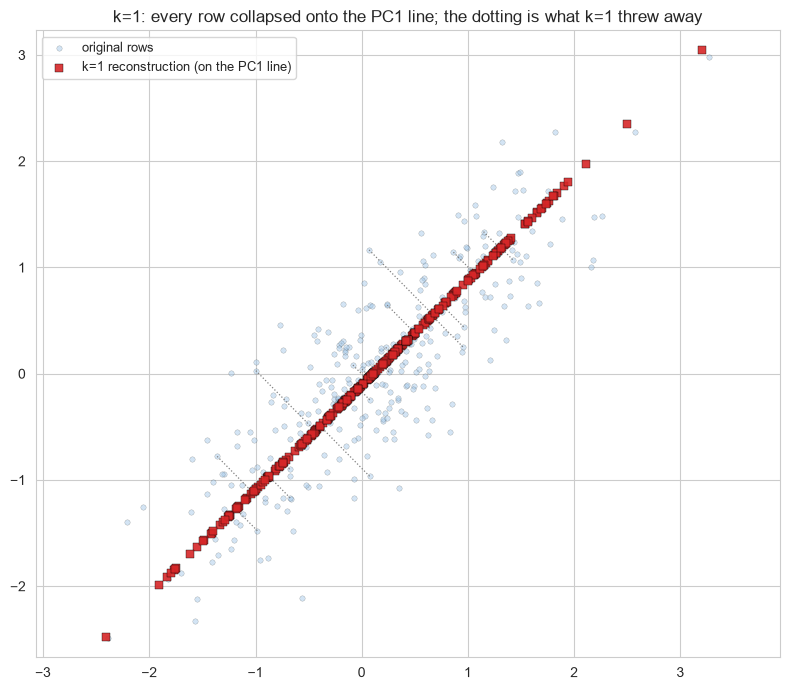

k=2 keeps both eigenvalues: max |X - X̂| = 8.9e-16  (exact rotation)
k=1 error = 0.1281  vs  leftover eigenvalue x (n-1)/n = 0.1281

💡 Add the second axis and the error vanishes; keep one and the error is EXACTLY the second
   eigenvalue (scaled by the ddof convention). Truncation is a controlled, predictable budget.


In [10]:
# The ladder, drawn in the 2-D original feature space of X2
pca_L1 = PCAScratch(n_components=1).fit(X2)
pca_L2 = PCAScratch(n_components=2).fit(X2)

Xhat1_L = pca_L1.inverse_transform(pca_L1.transform(X2))
Xhat2_L = pca_L2.inverse_transform(pca_L2.transform(X2))

fig, ax = plt.subplots(figsize=(8, 7))
ax.scatter(X2[:, 0], X2[:, 1], s=15, alpha=0.45, color="#9ec5e8",
           edgecolors="k", linewidths=0.2, label="original rows")
ax.scatter(Xhat1_L[:, 0], Xhat1_L[:, 1], s=26, color="#d62728", marker="s", alpha=0.9,
           edgecolors="k", linewidths=0.3, zorder=5, label="k=1 reconstruction (on the PC1 line)")
for p_row in range(0, len(X2), 12):                     # a light subsample of drop-lines
    ax.plot([X2[p_row, 0], Xhat1_L[p_row, 0]], [X2[p_row, 1], Xhat1_L[p_row, 1]],
            color="gray", ls=":", lw=0.9, zorder=4)
ax.axis("equal")
ax.set_title("k=1: every row collapsed onto the PC1 line; the dotting is what k=1 threw away")
ax.legend(fontsize=9, loc="upper left")
plt.tight_layout()
plt.show()

lam_sum_L = float(pca_L2.explained_variance_[1:].sum())
err_k1_L = float(((X2 - Xhat1_L) ** 2).sum(axis=1).mean())
print(f"k=2 keeps both eigenvalues: max |X - X̂| = {np.max(np.abs(X2 - Xhat2_L)):.1e}  (exact rotation)")
print(f"k=1 error = {err_k1_L:.4f}  vs  leftover eigenvalue x (n-1)/n = {lam_sum_L * (len(X2) - 1) / len(X2):.4f}")
print("\n💡 Add the second axis and the error vanishes; keep one and the error is EXACTLY the second")
print("   eigenvalue (scaled by the ddof convention). Truncation is a controlled, predictable budget.")

In [11]:
# The free sign: flip both the coordinates and the axis, nothing in feature space changes
pca_sg = PCAScratch(n_components=2).fit(X2)
Z_sg = pca_sg.transform(X2)
W_sg = pca_sg.components_

Z_alt = -Z_sg                    # the same rows, measured along the flipped-axis convention
W_alt = -W_sg
Xhat_alt = Z_alt @ W_alt + pca_sg.mean_

print(f"twin convention, PC1 loadings      : {np.round(W_sg[0], 4)}")
print(f"equally valid flipped convention   : {np.round(W_alt[0], 4)}")
print(f"max |recon(convention) - recon(flipped)| = {np.max(np.abs(pca_sg.inverse_transform(Z_sg) - Xhat_alt)):.1e}")
print(f"explained_variance ratio sum (both): {pca_sg.explained_variance_ratio_.sum():.12f}")
print("\n💡 A principal axis has no arrow. Twin and sklearn both fix the reading convention (largest")
print("   |loading| positive) so loadings compare cleanly across engines — but if you re-derive axes")
print("   with a different convention, flip the coordinates with them and every number that matters")
print("   (reconstructions, variances, ratios) stays identical.")

twin convention, PC1 loadings      : [0.7125 0.7017]
equally valid flipped convention   : [-0.7125 -0.7017]
max |recon(convention) - recon(flipped)| = 0.0e+00
explained_variance ratio sum (both): 1.000000000000

💡 A principal axis has no arrow. Twin and sklearn both fix the reading convention (largest
   |loading| positive) so loadings compare cleanly across engines — but if you re-derive axes
   with a different convention, flip the coordinates with them and every number that matters
   (reconstructions, variances, ratios) stays identical.


---

## 6. Implementation with Scikit-learn

scikit-learn's `PCA` solves the same eigenproblem through an **SVD of the centered data**: $X_c = U S V^\top$, with the kept components read off $V^\top$ and the variances off $S^2/(n-1)$. A few API facts worth pinning before the first fit:

- `fit` accepts a `y` for pipeline compatibility and ignores it — PCA never sees the target
- `svd_solver='auto'` resolves by shape. This 240 × 4 dataset (few features, n > 10 × d) lands on **`covariance_eigh`** — the exact covariance decomposition the twin hand-writes, so on THIS data the two engines run the same mathematics, not just equivalent mathematics
- The SVD path cannot produce negative eigenvalues; the covariance path can (numerically), which is why the twin clamps (§5) — and why sklearn's own `covariance_eigh` solver clamps too
- `transform` returns CENTERED projections: unwhitened coordinates carry the components' variances ($\lambda_i$), not the raw features' scale

In [12]:
print("=" * 60)
print("PCA (SCIKIT-LEARN) ON THE SAME DATA")
print("=" * 60)

pca_sk4 = PCA(n_components=4).fit(X4)
print(f"\n🌀 Fitted attributes (superset of the twin's):")
print(f"  explained_variance_        : {np.round(pca_sk4.explained_variance_, 4)}")
print(f"  explained_variance_ratio_  : {np.round(pca_sk4.explained_variance_ratio_, 4)}")
print(f"  singular_values_           : {np.round(pca_sk4.singular_values_, 3)}"
      f"   (= sqrt((n-1) λ): {np.round(np.sqrt((len(X4) - 1) * pca_sk4.explained_variance_), 3)})")
print(f"  noise_variance_            : {pca_sk4.noise_variance_:.1e}"
      f"   (average of the min(n,d) - k smallest λ; PPCA's noise estimate — 0 at full rank)")
print(f"  n_components_ / n_samples_ : {pca_sk4.n_components_} / {pca_sk4.n_samples_}")
print(f"  mean_ matches X4.mean()    : {np.allclose(pca_sk4.mean_, X4.mean(axis=0))}")

Sigma4 = np.cov(X4, rowvar=False)
cov_hat = pca_sk4.get_covariance()
print(f"\n🔍 get_covariance() vs the empirical Σ (ddof=1): max abs diff = "
      f"{np.max(np.abs(cov_hat - Sigma4)):.1e}   (exact at full rank — same matrix, two routes)")
print("\n💡 sklearn exposes the SVD-shaped view of the same spectrum: singular values are coordinate")
print("   2-norms, and noise_variance_ is the PPCA model's leftover-noise estimate (Tipping & Bishop),")
print("   which is only interesting BELOW full rank — see the variants cell later.")

PCA (SCIKIT-LEARN) ON THE SAME DATA

🌀 Fitted attributes (superset of the twin's):
  explained_variance_        : [2.843  0.5976 0.2431 0.0822]
  explained_variance_ratio_  : [0.7549 0.1587 0.0646 0.0218]
  singular_values_           : [26.067 11.951  7.623  4.433]   (= sqrt((n-1) λ): [26.067 11.951  7.623  4.433])
  noise_variance_            : 0.0e+00   (average of the min(n,d) - k smallest λ; PPCA's noise estimate — 0 at full rank)
  n_components_ / n_samples_ : 4 / 240
  mean_ matches X4.mean()    : True

🔍 get_covariance() vs the empirical Σ (ddof=1): max abs diff = 1.3e-15   (exact at full rank — same matrix, two routes)

💡 sklearn exposes the SVD-shaped view of the same spectrum: singular values are coordinate
   2-norms, and noise_variance_ is the PPCA model's leftover-noise estimate (Tipping & Bishop),
   which is only interesting BELOW full rank — see the variants cell later.


### Dual Engine: Scratch vs Scikit-learn on the Same Data

What should match, and what cannot, bit-for-bit:

- **explained_variance_ / ratios**: compared element-wise — both sides deliver them in descending order, so no permutation or sign alignment is needed (the behavioral tests assert `atol=1e-8` here)
- **components_ / transform projections**: equal **up to each axis' sign** — the eigendirection is a line, and the two engines fix signs differently until the convention makes them comparable; the twin's largest-|loading| rule + a sign alignment closes the gap
- The residuals are float-level: SVD-of-data vs eigh-of-covariance are different numerical roads, documented as such in the twin's module

In [13]:
print("=" * 60)
print("DUAL ENGINE: PCAScratch vs SCIKIT-LEARN ON THE SAME DATA")
print("=" * 60)

scratch_d = PCAScratch(n_components=2).fit(X4)
sk_d = PCA(n_components=2).fit(X4)


def align_cols(A, B):
    # Flip each COLUMN of A so it points the same way as B's matching column
    return A * np.sign((A * B).sum(axis=0, keepdims=True))


def align_rows(A, B):
    # Flip each ROW of A so it points the same way as B's matching row
    return A * np.sign((A * B).sum(axis=1, keepdims=True))


proj_s_d = scratch_d.transform(X4)
proj_k_d = sk_d.transform(X4)

checks_d = [
    ("explained_variance_ (direct)", np.allclose(scratch_d.explained_variance_,
                                                 sk_d.explained_variance_, atol=1e-8)),
    ("explained_variance_ratio_ (direct)", np.allclose(scratch_d.explained_variance_ratio_,
                                                       sk_d.explained_variance_ratio_, atol=1e-8)),
    ("components_ (sign-aligned)", np.allclose(align_rows(scratch_d.components_, sk_d.components_),
                                               sk_d.components_, atol=1e-8)),
    ("transform projections (column sign-aligned)", np.allclose(align_cols(proj_s_d, proj_k_d),
                                                                proj_k_d, atol=1e-8)),
    ("ratios sum to the same kept share", np.isclose(scratch_d.explained_variance_ratio_.sum(),
                                                     sk_d.explained_variance_ratio_.sum())),
]
checks_df = pd.DataFrame(checks_d, columns=["check (mirrors tests/models/test_dimensionality_reduction.py)",
                                            "result"])
print(checks_df.to_string(index=False))
print(f"\nmax |ratio diff| = {np.max(np.abs(scratch_d.explained_variance_ratio_ - sk_d.explained_variance_ratio_)):.1e}"
      f"   max |component diff| after sign alignment = "
      f"{np.max(np.abs(align_rows(scratch_d.components_, sk_d.components_) - sk_d.components_)):.1e}")
print("💡 Same eigenproblem, same spectrum, two numerical roads (eigh vs SVD). The tests pin the")
print("   agreement at 1e-8 and the twin's sign rule is what makes ''up to sign'' a solved problem.")

DUAL ENGINE: PCAScratch vs SCIKIT-LEARN ON THE SAME DATA
check (mirrors tests/models/test_dimensionality_reduction.py)  result
                                 explained_variance_ (direct)    True
                           explained_variance_ratio_ (direct)    True
                                   components_ (sign-aligned)    True
                  transform projections (column sign-aligned)    True
                            ratios sum to the same kept share    True

max |ratio diff| = 1.1e-16   max |component diff| after sign alignment = 7.8e-16
💡 Same eigenproblem, same spectrum, two numerical roads (eigh vs SVD). The tests pin the
   agreement at 1e-8 and the twin's sign rule is what makes ''up to sign'' a solved problem.


### Scikit-learn-Only Extras (the twin skips these on purpose)

Three clusters of extras the exact twin does not carry:

- **Whitening** (`whiten=True`): rescales each coordinate to unit variance (isotropic outputs), trading away the relative-variance information. Only worth it when the downstream model assumes spherical, equal-variance inputs
- **Probabilistic PCA** (`score`, `score_samples`, `get_precision`, `noise_variance_`): the Tipping & Bishop model wraps the same spectrum in a likelihood; useful for model comparison and for cross-validated noise estimation — not part of the twin's exactness story
- **The family variants**: `KernelPCA` (linear PCA in a kernel-induced space — nonlinear structure), `SparsePCA` (loadings with zeros — interpretable components), `IncrementalPCA` (streamed batches — huge or out-of-core data), and `TruncatedSVD` (the same machine without centering — sparse matrices; §11 contrasts it)

coordinate std per component (ddof=1):
  unwhitened: [1.686 0.773 0.493 0.287]   <- sqrt(λ_i): the raw PCA coordinates
  whitened  : [1. 1. 1. 1.]   <- ~1.0 each: every axis normalized (n/(n-1) rounding on top)

probabilistic PCA (k=2):
  score(X)            = -4.1163   (average per-row log-likelihood)
  score_samples(X)[0:3] = [-2.591 -4.201 -3.305]
  get_precision() has the feature-space shape (4, 4)


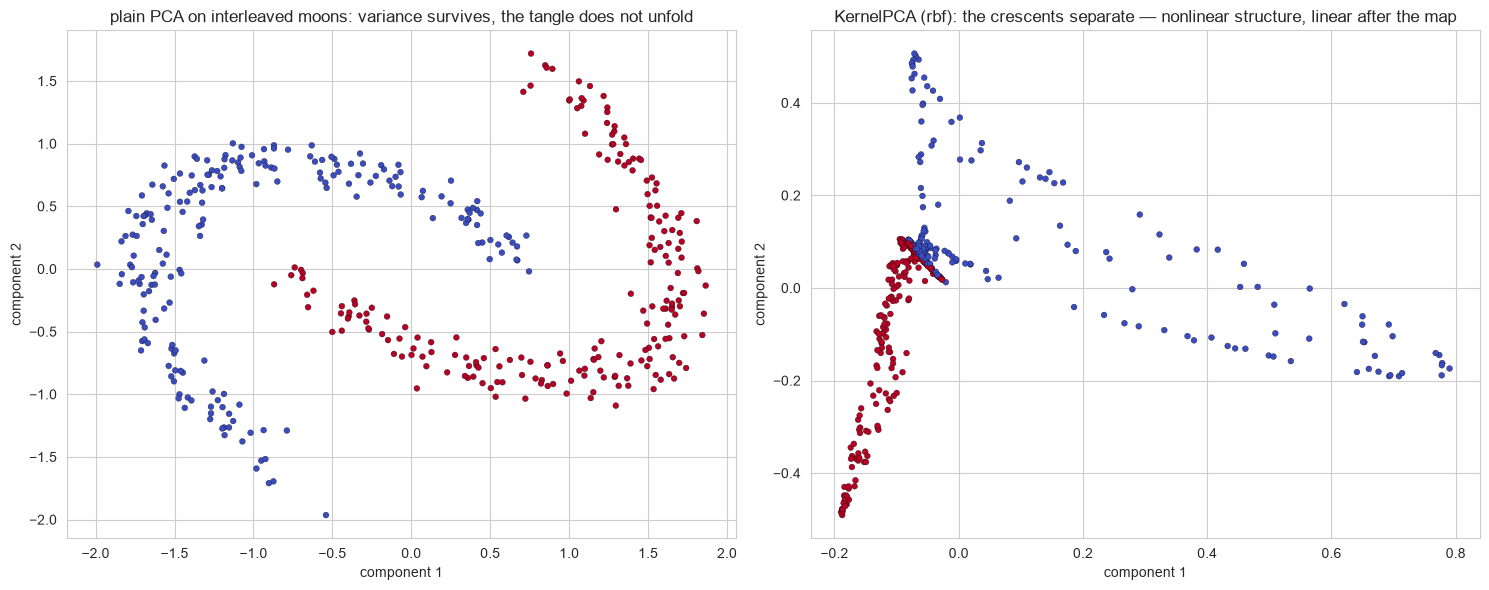


SparsePCA loadings on the standardized 4-feature set (alpha=0.5):
   f0    f1    f2    f3
0.655 0.625 0.424 0.000
0.000 0.105 0.404 0.909
nonzeros per component: [3, 3]   (vs 4/4 for every plain PCA axis on this data)

IncrementalPCA(2, batch 120) vs PCA(2) ratio diff: 2.74e-05

💡 Variants are qualifiers, not upgrades: KernelPCA for curved manifolds, SparsePCA when the
   loadings must be read, IncrementalPCA when the data does not fit memory. Plain PCA stays
   the deterministic baseline; tune KernelPCA's gamma like an SVM width (notebook 05, §7).


In [14]:
# 1) Whitening: unit-variance coordinates, relative scales traded away
pca_uw = PCA(n_components=4).fit(X4)
pca_wh = PCA(n_components=4, whiten=True).fit(X4)
print("coordinate std per component (ddof=1):")
print(f"  unwhitened: {np.round(pca_uw.transform(X4).std(axis=0, ddof=1), 3)}"
      f"   <- sqrt(λ_i): the raw PCA coordinates")
print(f"  whitened  : {np.round(pca_wh.transform(X4).std(axis=0, ddof=1), 3)}"
      f"   <- ~1.0 each: every axis normalized (n/(n-1) rounding on top)")

# 2) Probabilistic PCA extras: a likelihood view of the same spectrum
pca_pp = PCA(n_components=2).fit(X4)
print(f"\nprobabilistic PCA (k=2):")
print(f"  score(X)            = {float(pca_pp.score(X4)):.4f}   (average per-row log-likelihood)")
print(f"  score_samples(X)[0:3] = {np.round(pca_pp.score_samples(X4)[:3], 3)}")
print(f"  get_precision() has the feature-space shape {pca_pp.get_precision().shape}")

# 3) Family variants, each one small tool with one sentence of justification
X_mn, y_mn = make_moons(n_samples=400, noise=0.07, random_state=42)
X_mn_s = StandardScaler().fit_transform(X_mn)
Z_mn_lin = PCA(n_components=2).fit_transform(X_mn_s)
Z_mn_ker = KernelPCA(n_components=2, kernel="rbf", gamma=15.0).fit_transform(X_mn_s)

fig, axes = plt.subplots(1, 2, figsize=(15, 6))
axes[0].scatter(Z_mn_lin[:, 0], Z_mn_lin[:, 1], c=y_mn, cmap="coolwarm", s=18, edgecolors="k",
                linewidths=0.2)
axes[0].set_title("plain PCA on interleaved moons: variance survives, the tangle does not unfold")
axes[1].scatter(Z_mn_ker[:, 0], Z_mn_ker[:, 1], c=y_mn, cmap="coolwarm", s=18, edgecolors="k",
                linewidths=0.2)
axes[1].set_title("KernelPCA (rbf): the crescents separate — nonlinear structure, linear after the map")
for ax_gr in axes:
    ax_gr.set_xlabel("component 1")
    ax_gr.set_ylabel("component 2")
plt.tight_layout()
plt.show()

# Sparse loadings: zeros you can read
pca_sparse = SparsePCA(n_components=2, alpha=0.5, random_state=0).fit(X4_std)
sparse_loads = pd.DataFrame(np.round(pca_sparse.components_, 3),
                            columns=[f"f{j}" for j in range(X4_std.shape[1])])
print("\nSparsePCA loadings on the standardized 4-feature set (alpha=0.5):")
print(sparse_loads.to_string(index=False))
print(f"nonzeros per component: {[int((row != 0).sum()) for row in pca_sparse.components_]}"
      f"   (vs 4/4 for every plain PCA axis on this data)")

# Streaming: IncrementalPCA reaches the full fit in fixed-memory batches
pca_stream = IncrementalPCA(n_components=2, batch_size=120).fit(X4)
print(f"\nIncrementalPCA(2, batch 120) vs PCA(2) ratio diff: "
      f"{np.max(np.abs(pca_stream.explained_variance_ratio_ - sk_d.explained_variance_ratio_)):.2e}")
print("\n💡 Variants are qualifiers, not upgrades: KernelPCA for curved manifolds, SparsePCA when the")
print("   loadings must be read, IncrementalPCA when the data does not fit memory. Plain PCA stays")
print("   the deterministic baseline; tune KernelPCA's gamma like an SVM width (notebook 05, §7).")

---

## 7. Hyperparameter Tuning

For the exact decomposition there is exactly **one decision that changes the information budget: k** (scikit-learn adds solver/whiten knobs — §8 — but neither changes what the spectrum says). Four honest ways to choose it, all on **training data only**:

1. **Cumulative explained variance** — keep the smallest k that clears a target (90–95% is the common reflex; the app card's red marker does precisely this)
2. **Scree elbow** — the knee where added components stop paying for themselves
3. **The Kaiser rule** (standardized features only) — keep components with $\lambda > 1$: each carried more variance than one full standardized feature
4. **Downstream cross-validation** — treat k as a pipeline hyperparameter and let a CV score decide; the right tool whenever PCA serves a model rather than a viewer

A fifth view, the **reconstruction budget** (project the dropped-eigenvalue sum), is useful when faithful rendering matters more than downstream performance. Below: the spectrum of the companion 4-feature data and of a wider 8-feature set with a visible elbow, then the error-budget curve, then the downstream CV protocol.

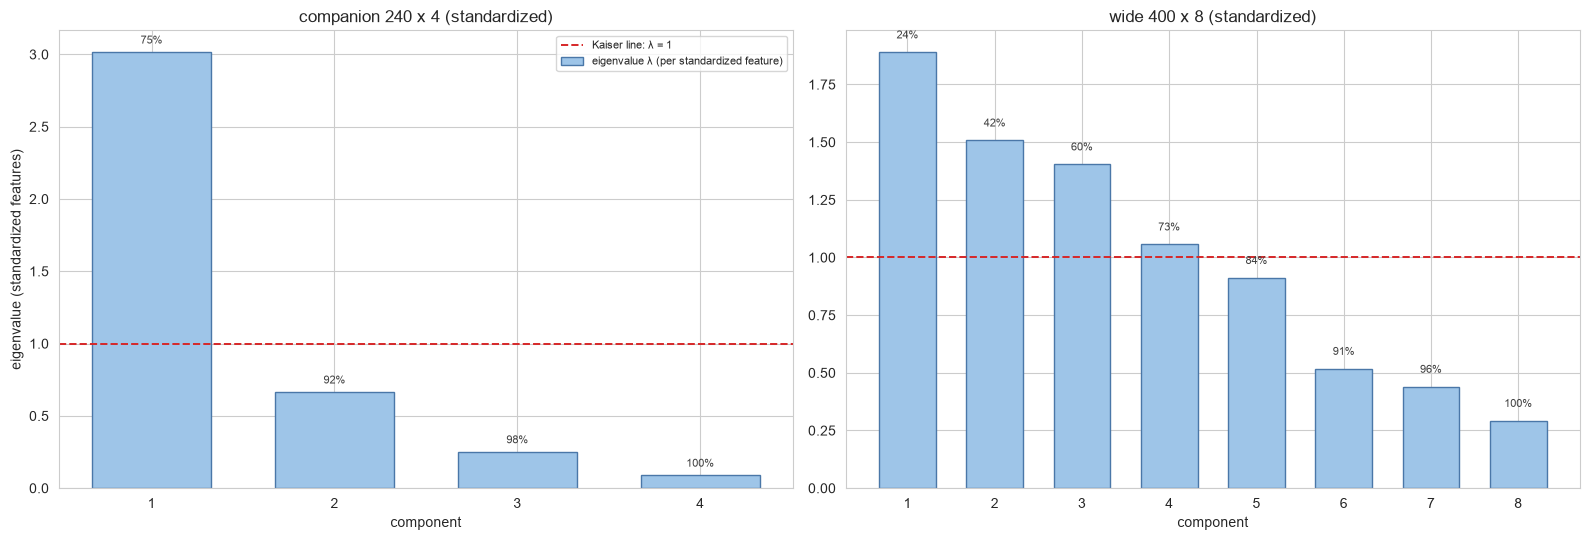

companion 4f: Kaiser components = 1   |   first k reaching 90% = 2   |   cumulative = [0.751 0.916 0.978 1.   ]
     wide 8f: Kaiser components = 4   |   first k reaching 90% = 6   |   cumulative = [0.236 0.424 0.599 0.731 0.844 0.909 0.964 1.   ]

💡 On standardized data the Kaiser line reads 'carries more than one whole feature's variance'.
   Bar heights are fixed properties of the dataset — choosing k is choosing WHERE TO CUT the
   cumulative line, never re-weighting the bars.


In [15]:
# The wider spectrum set: 400 x 8 with decaying variances and three correlated pairs
rng8 = np.random.default_rng(1)
scales8 = np.array([6.0, 4.0, 2.5, 1.6, 1.2, 1.0, 0.85, 0.7])
cov8 = np.diag(scales8 ** 2)
cov8[0, 1] = cov8[1, 0] = 0.6 * scales8[0] * scales8[1]
cov8[2, 3] = cov8[3, 2] = 0.7 * scales8[2] * scales8[3]
cov8[4, 5] = cov8[5, 4] = 0.5 * scales8[4] * scales8[5]
X8 = rng8.multivariate_normal(np.zeros(8), cov8, size=400)
X8_std = StandardScaler().fit_transform(X8)     # standardized: PCA = correlation structure, Kaiser applies

pca_k4std = PCAScratch().fit(X4_std)
pca_k8std = PCAScratch().fit(X8_std)

fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
for ax_car, (label, model_car) in zip(axes, [("companion 240 x 4 (standardized)", pca_k4std),
                                             ("wide 400 x 8 (standardized)", pca_k8std)]):
    ks_car = np.arange(1, model_car.n_components_ + 1)
    ax_car.bar(ks_car, model_car.explained_variance_, color="#9ec5e8", edgecolor="#4a77a8", width=0.65,
               label="eigenvalue λ (per standardized feature)")
    ax_car.axhline(1.0, color="#d62728", ls="--", lw=1.4, label="Kaiser line: λ = 1")
    cum_car = np.cumsum(model_car.explained_variance_ratio_)
    for j in ks_car:
        ax_car.text(j, model_car.explained_variance_[j - 1] + 0.06, f"{cum_car[j - 1]:.0%}",
                    ha="center", fontsize=8, color="#404040")
    ax_car.set_xticks(ks_car)
    ax_car.set_xlabel("component")
    ax_car.set_title(label)
axes[0].set_ylabel("eigenvalue (standardized features)")
axes[0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

for tag, model_tab in [("companion 4f", pca_k4std), ("wide 8f", pca_k8std)]:
    cum_tab = np.cumsum(model_tab.explained_variance_ratio_)
    kaiser_tab = int((model_tab.explained_variance_ > 1.0).sum())
    k90 = int(np.searchsorted(cum_tab, 0.90) + 1)
    print(f"{tag:>12s}: Kaiser components = {kaiser_tab}   |   first k reaching 90% = {k90}   |   "
          f"cumulative = {np.round(cum_tab, 3)}")
print("\n💡 On standardized data the Kaiser line reads 'carries more than one whole feature's variance'.")
print("   Bar heights are fixed properties of the dataset — choosing k is choosing WHERE TO CUT the")
print("   cumulative line, never re-weighting the bars.")

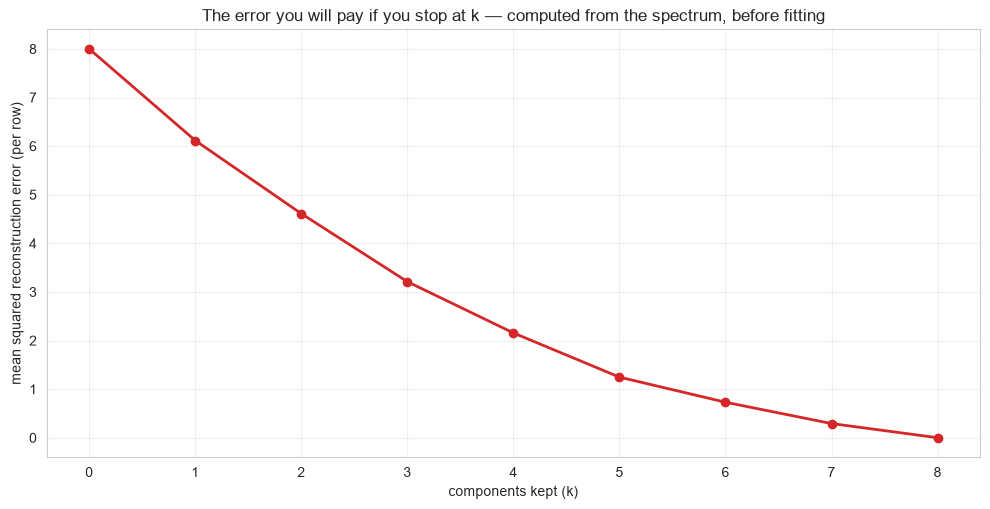

  k | error (plain per row) | as share of total spread
  0 |                8.0000 |                  100.0%
  2 |                4.6108 |                   57.6%
  4 |                2.1559 |                   26.9%
  6 |                0.7302 |                    9.1%
  8 |                0.0000 |                    0.0%

💡 Stopping at k costs exactly the eigenvalues you dropped. 'How faithful must the rendering
   be' converts straight into a k choice — no training, no CV, no seeds.


In [16]:
# The reconstruction budget: mean squared error if you stop at k — known from the spectrum alone
lam8 = pca_k8std.explained_variance_
factor8 = (len(X8_std) - 1) / len(X8_std)            # ddof=1 -> plain per-row mean needs (n-1)/n
ks_budget = np.arange(0, len(lam8) + 1)
errs_budget = np.array([lam8[k:].sum() * factor8 for k in ks_budget])   # sum of the dropped λ

fig, ax = plt.subplots(figsize=(10, 5.2))
ax.plot(ks_budget, errs_budget, "o-", color="#d62728", lw=2)
ax.set_xlabel("components kept (k)")
ax.set_ylabel("mean squared reconstruction error (per row)")
ax.set_title("The error you will pay if you stop at k — computed from the spectrum, before fitting")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

rel_budget = errs_budget / errs_budget[0]
print(f"{'k':>3s} | {'error (plain per row)':>21s} | {'as share of total spread':>24s}")
for idx_budget in range(0, len(ks_budget), 2):
    print(f"{idx_budget:3d} | {errs_budget[idx_budget]:21.4f} | {rel_budget[idx_budget]:23.1%}")
print("\n💡 Stopping at k costs exactly the eigenvalues you dropped. 'How faithful must the rendering")
print("   be' converts straight into a k choice — no training, no CV, no seeds.")

### Choosing k by Downstream Cross-Validation

When PCA is preprocessing for a model, k belongs in the **Pipeline**, tuned by CV like any other hyperparameter. The protocol:

1. `Pipeline(StandardScaler → PCA(n_components=k) → LogisticRegression)` — the scaler and the PCA are refit on every fold's training rows only
2. `GridSearchCV` over a k grid (plus a baseline without the rotation)
3. Report the held-out test set **once**, with the chosen k

The breast cancer set (30 correlated measurements) makes a realistic stage: its features are correlated enough for real compression, and its downstream accuracy is the target rather than a proxy.

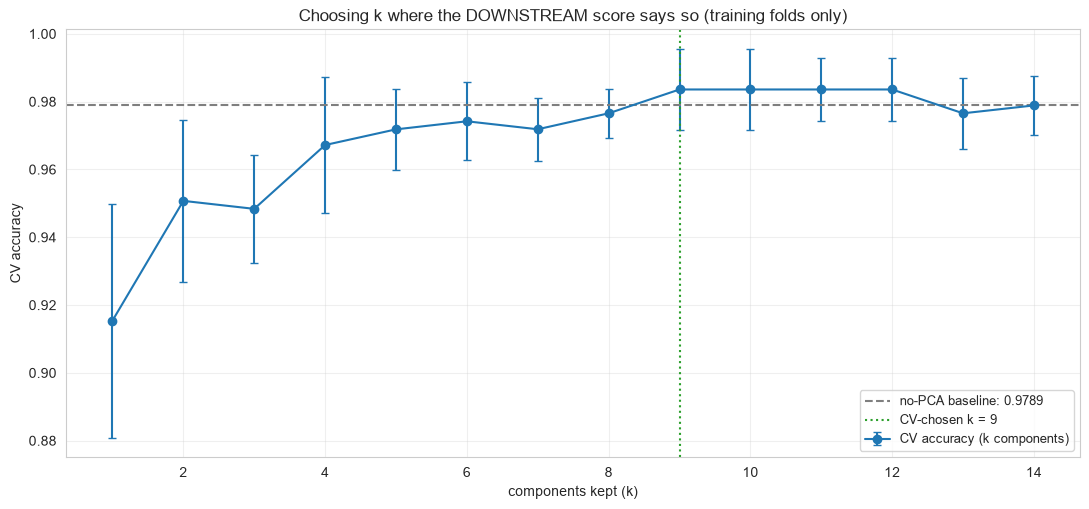

best k (CV): 9   |   best CV accuracy: 0.9836
no-PCA baseline CV accuracy: 0.9789
held-out test accuracy with the CV-chosen k: 0.9790
variance kept by the chosen k: 94.2% of the standardized features' spread

💡 The pipeline refits scaler AND PCA inside every fold, so no statistic crosses the fold
   boundary. Expect the CV curve to be flat near the full-rank k: PCA is a ROTATION, and the
   accuracy loss arrives only when k cuts into the signal (the §11 demo shows the hard case).


In [17]:
bc = load_breast_cancer()
Xb_tr, Xb_te, yb_tr, yb_te = train_test_split(bc.data, bc.target, test_size=0.25,
                                              stratify=bc.target, random_state=42)

pipe_bc = Pipeline([("sc", StandardScaler()), ("pca", PCA()), ("clf", LogisticRegression(max_iter=5000))])
k_grid_bc = list(range(1, 15))
search_bc = GridSearchCV(
    pipe_bc,
    {"pca__n_components": k_grid_bc},
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy",
    n_jobs=-1,
)
search_bc.fit(Xb_tr, yb_tr)

baseline_bc = cross_val_score(
    Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]),
    Xb_tr, yb_tr,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring="accuracy", n_jobs=-1,
)

cum_bc = np.cumsum(PCA().fit(StandardScaler().fit_transform(Xb_tr)).explained_variance_ratio_)
cv_table_bc = pd.DataFrame(search_bc.cv_results_)[["param_pca__n_components", "mean_test_score",
                                                   "std_test_score"]]
best_k_bc = int(search_bc.best_params_["pca__n_components"])

fig, ax = plt.subplots(figsize=(11, 5.2))
ax.errorbar(k_grid_bc, cv_table_bc["mean_test_score"], yerr=cv_table_bc["std_test_score"],
            fmt="o-", color="#1f77b4", capsize=3, label="CV accuracy (k components)")
ax.axhline(baseline_bc.mean(), color="#7f7f7f", ls="--", lw=1.5,
           label=f"no-PCA baseline: {baseline_bc.mean():.4f}")
ax.axvline(best_k_bc, color="#2ca02c", ls=":", lw=1.5, label=f"CV-chosen k = {best_k_bc}")
ax.set_xlabel("components kept (k)")
ax.set_ylabel("CV accuracy")
ax.set_title("Choosing k where the DOWNSTREAM score says so (training folds only)")
ax.legend(fontsize=9, loc="lower right")
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

print(f"best k (CV): {best_k_bc}   |   best CV accuracy: {search_bc.best_score_:.4f}")
print(f"no-PCA baseline CV accuracy: {baseline_bc.mean():.4f}")
print(f"held-out test accuracy with the CV-chosen k: {search_bc.best_estimator_.score(Xb_te, yb_te):.4f}")
print(f"variance kept by the chosen k: {cum_bc[best_k_bc - 1]:.1%} of the standardized features' spread")
print("\n💡 The pipeline refits scaler AND PCA inside every fold, so no statistic crosses the fold")
print("   boundary. Expect the CV curve to be flat near the full-rank k: PCA is a ROTATION, and the")
print("   accuracy loss arrives only when k cuts into the signal (the §11 demo shows the hard case).")

### Solvers, Seeds, and the Other `n_components` Forms

The exact spectrum does not care which solver computes it — but the API has choices, and they are worth one consistency check:

- **`full`** (exact LAPACK SVD), **`covariance_eigh`** (covariance + `eigh` — the twin's road) and **`randomized`** (Halko-style probabilistic SVD) return the same ratios to float precision; `arpack` truncates with an iterative solver
- `random_state` is honored ONLY by `randomized` and `arpack`; the exact paths have nothing random to seed
- `n_components` has three other forms: a **float in (0, 1)** (keep enough components to clear that variance share; requires `svd_solver='full'`, see §8's table) and **`'mle'`** (Minka's automatic dimensionality estimate)

In [18]:
k_solver = 3
reference_full = PCA(n_components=k_solver, svd_solver="full").fit(X8_std)

rows_solver = []
for solver_name in ["full", "covariance_eigh", "randomized", "arpack"]:
    t0_solver = time.perf_counter()
    model_solver = PCA(n_components=k_solver, svd_solver=solver_name, random_state=0).fit(X8_std)
    dt_solver = time.perf_counter() - t0_solver
    diff_solver = float(np.max(np.abs(model_solver.explained_variance_ratio_
                                      - reference_full.explained_variance_ratio_)))
    rows_solver.append({"svd_solver": solver_name,
                        "max ratio diff vs full": diff_solver,
                        "fit (s)": dt_solver})
solver_df = pd.DataFrame(rows_solver)
print(solver_df.to_string(index=False, float_format=lambda v: f"{v:.3g}"))

seed_a = PCA(n_components=k_solver, svd_solver="randomized", random_state=0).fit(X8_std)
seed_b = PCA(n_components=k_solver, svd_solver="randomized", random_state=1).fit(X8_std)
print(f"\nrandomized solver across seeds: identical with the same seed, "
      f"max ratio diff with a different seed = "
      f"{np.max(np.abs(seed_a.explained_variance_ratio_ - seed_b.explained_variance_ratio_)):.1e}")

frac_fit = PCA(n_components=0.90, svd_solver="full").fit(X8_std)
mle_fit = PCA(n_components="mle", svd_solver="full").fit(X8_std)
print(f"\nn_components=0.90 resolved to k = {frac_fit.n_components_} "
      f"(cumulative ratio {np.cumsum(frac_fit.explained_variance_ratio_)[-1]:.2%})")
print(f"n_components='mle' resolved  to k = {mle_fit.n_components_}")
print("\n💡 Solving the same eigenproblem with four different engines moves the ratios at the 1e-15")
print("   level. Seeds enter only where the solver is probabilistic. And sklearn can even pick k FOR")
print("   you (0.90 share, Minka's MLE) — deterministic, though never as informative as the CV curve.")

     svd_solver  max ratio diff vs full  fit (s)
           full                       0 0.000374
covariance_eigh                 2.5e-16 0.000432
     randomized                1.94e-16  0.00584
         arpack                 2.5e-16  0.00283

randomized solver across seeds: identical with the same seed, max ratio diff with a different seed = 2.5e-16

n_components=0.90 resolved to k = 6 (cumulative ratio 90.87%)
n_components='mle' resolved  to k = 7

💡 Solving the same eigenproblem with four different engines moves the ratios at the 1e-15
   level. Seeds enter only where the solver is probabilistic. And sklearn can even pick k FOR
   you (0.90 share, Minka's MLE) — deterministic, though never as informative as the CV curve.


---

## 8. Complete Hyperparameter Reference

### sklearn `PCA` Parameters (documented against scikit-learn 1.9, the repo's pin)

#### `n_components` (int, float, 'mle' or None, default=None) **[THE HYPERPARAMETER]**
- **None**: keep all — `min(n_samples, n_features)` components (with `arpack`: one less)
- **int**: keep exactly that many. Constraint is `[1, min(n_samples, n_features)]` for the exact solvers; `arpack` requires strictly less than `min(n_samples, n_features)`
- **float in (0, 1)**: keep the smallest prefix whose cumulative variance share clears the value (e.g. `0.95`). Supported with `svd_solver='full'` (demonstrated in §7's solver cell)
- **'mle'**: Minka's automatic dimension estimate from the likelihood of the probabilistic model; the `'auto'` solver behaves as `'full'` when this is set
- **Effect**: k selects a prefix of the already-computed spectrum — it never changes the axes themselves
- **Example**: `PCA(n_components=0.95)`

#### `copy` (bool, default=True)
- `fit` copies the input before centering; with `copy=False`, fit OVERWRITES the array you passed (and `fit(X).transform(X)` no longer returns what you'd expect — use `fit_transform(X)`)
- Keep the default unless memory forces otherwise; **Example**: `PCA(copy=False)` only for huge already-disposable arrays

#### `whiten` (bool, default=False)
- Multiplies each kept coordinate by `sqrt(n_samples)` / its singular value: outputs become uncorrelated WITH unit variance (~1 per coordinate)
- Trades away the relative variance scales (each axis is weighted equally) — occasionally helps downstream estimators that prefer isotropic inputs. Otherwise leave it off
- **Example**: `PCA(whiten=True)` when the downstream model expects spheres

#### `svd_solver` ({'auto', 'full', 'covariance_eigh', 'arpack', 'randomized'}, default='auto')
- **'auto'** policy from the data's shape: `covariance_eigh` when `n_features < 1000` **and** `n_samples > 10 × n_features`; `randomized` when the data exceeds 500 × 500 **and** the number of components is below 80% of the smallest dimension; otherwise `full`
- **'full'**: exact LAPACK SVD of the centered data, then slice
- **'covariance_eigh'** (added in 1.5): build the covariance, `eigh` it — the twin's road; cheapest exact path for `n ≫ d`, but it squares the condition number, so very ill-conditioned data prefers full SVD
- **'arpack'**: truncated ARPACK SVD; requires `0 < n_components < min(X.shape)`; works on sparse input
- **'randomized'** (Halko et al.): probabilistic truncated SVD; the speed king for huge n with k ≪ min(X.shape)
- **Example**: `PCA(svd_solver='randomized', n_components=50)`

#### `tol` (float, default=0.0)
- Tolerance for the singular values computed by `svd_solver='arpack'` only

#### `iterated_power` (int or 'auto', default='auto')
- Number of power-method iterations inside the `randomized` solver; `'auto'` picks it from the size of the data. More iterations, better approximation

#### `n_oversamples` (int, default=10)
- `randomized` solver only: extra random probe vectors that condition the approximation (since 1.1)

#### `power_iteration_normalizer` ({'auto', 'QR', 'LU', 'none'}, default='auto')
- `randomized` solver only: how the power iterations are re-normalized (since 1.1)

#### `random_state` (int, RandomState or None, default=None)
- Used ONLY by the `'arpack'` and `'randomized'` solvers; the exact paths (`full`, `covariance_eigh`) have nothing random to seed — the twin's determinism is sklearn's determinism

### Fitted Attributes (superset of the twin's)

| Attribute | Shape / type | Note |
|---|---|---|
| `components_` | (n_components, n_features) | principal axes; rows, sorted by decreasing variance |
| `explained_variance_` | (n_components,) | λ_i = s_i² / (n − 1) |
| `explained_variance_ratio_` | (n_components,) | λ_i / Σ_j λ_j; sums to 1.0 only when ALL components are kept |
| `singular_values_` | (n_components,) | coordinate 2-norms per component (since 0.19) |
| `mean_` | (n_features,) | the per-feature training mean that centering subtracts |
| `n_components_` | int | the RESOLVED k (useful with 'mle'/float/None forms) |
| `n_samples_` | int | rows seen during fit |
| `noise_variance_` | float | average of the min(n, d) − k smallest λ — the PPCA noise estimate (0 at full rank) |
| `n_features_in_`, `feature_names_in_` | int, array | input bookkeeping (DataFrame column names land here) |

### Methods Worth Knowing

| Method | Does |
|---|---|
| `fit(X[, y])`, `transform(X)`, `fit_transform(X)`, `inverse_transform(X)` | the transform quartet; `inverse_transform` maps coordinates back to feature space |
| `get_covariance()` | the model's estimated covariance (exact equal to the empirical Σ at full rank) |
| `get_precision()` | its inverse, via the matrix-inversion lemma of the PPCA model |
| `score(X)`, `score_samples(X)` | average / per-row log-likelihood under the Probabilistic PCA model |
| `get_feature_names_out()` | pipeline-compatible output names ("pca0", "pca1", ...) |

### Scratch Twin Coverage

The coverage table below mirrors what the behavioral suite (`tests/models/test_dimensionality_reduction.py`) pins down:

| scikit-learn `PCA` | `PCAScratch` | Notes |
|---|---|---|
| `n_components` int/None | ✅ | same semantics; validated in fit |
| `n_components` float/'mle' | ❌ | int-or-None by design |
| `copy`, `whiten` | ❌ | the twin never mutates inputs (casts to float64) and never rescales |
| `svd_solver`, `tol`, `iterated_power`, `n_oversamples`, `power_iteration_normalizer` | ❌ | ONE exact path (ddof=1 covariance + eigh) |
| `random_state` | — | not a constructor parameter: nothing in the exact path is random |
| `components_`, `explained_variance_`, `explained_variance_ratio_`, `mean_`, `n_components_` | ✅ | same names, same shapes, same orderings |
| `singular_values_`, `noise_variance_`, `n_samples_`, `n_features_in_`, `feature_names_in_` | ❌ | reconstructable by hand (§2, §5) but not exposed |
| `transform`, `inverse_transform`, `fit_transform` | ✅ | identical algebra |
| `score`, `score_samples`, `get_covariance`, `get_precision`, `get_feature_names_out` | ❌ | probabilistic/pipeline extras |

### Parameter Combination Recipes

#### Compression with a variance share (scaler first, always):
```python
Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=0.95))])
```

#### k by downstream CV (the §7 protocol):
```python
GridSearchCV(pipe, {"pca__n_components": range(1, 15)},
             cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42))
```

#### Deterministic 2-D map for plotting:
```python
PCA(n_components=2).fit_transform(StandardScaler().fit_transform(X))
```

#### Huge n / streaming / memory-bounded:
```python
IncrementalPCA(n_components=50, batch_size=512)    # .partial_fit() for out-of-core
PCA(n_components=50, svd_solver="randomized", random_state=0)
```

#### Nonlinear structure or readable loadings:
```python
KernelPCA(n_components=2, kernel="rbf", gamma=15.0)
SparsePCA(n_components=5, alpha=1.0)
```

#### Sparse matrices (un-centered SVD is the native sparse path):
```python
TruncatedSVD(n_components=100)          # sparse data; PCA accepts sparse only via 'arpack'
```

#### The scratch twin:
```python
PCAScratch(n_components=2)              # exact, deterministic, int-or-None k

---

## 9. Practical Tips & Common Pitfalls

### ✅ Best Practices

#### 1. **Standardize Before Fitting — Inside the Pipeline**
Scaling decides what PCA hears (§2). Put the scaler in front and let CV refit it per fold:
```python
Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=k)), ("clf", ...)]).fit(X_train, y_train)
```

---

#### 2. **Fit Statistics on Training Rows — Everything Through the Fitted Pipe**
The PCA is a fitted transform like any other: training rows set `mean_`, `components_` (and the scaler's stats); validation/test rows are only ever `transform`ed by the fitted pipe. Never re-fit on data that includes the evaluation set.

---

#### 3. **Choose k Deliberately, and Say Which Rule You Used**
- Serving a model: k by downstream CV (§7's protocol) — the only rule that optimizes what you ship
- Compression/visualization: cumulative variance ≥ a stated target, a scree elbow, or an explicit reconstruction budget
- Document the rule in the pipeline/artifact so the choice survives the next refactor

---

#### 4. **Read the Loadings, Don't Re-Name the Components**
`components_[i]` is component i's recipe over the ORIGINAL features. With `feature_names_in_` (or your own labels) the top-|loading| features tell you what each axis measures. The ± of an axis is convention (§7's sign cell) — flip it freely when it helps reading, never interpret it causally.

---

#### 5. **`fit_transform` for the Same Rows, `transform` for Later Ones**
Double-centering by hand is the classic bug: `fit(X).transform(X)` re-centers an already-centered view internally in sklearn (the docs warn `copy=False` breaks this pattern); use `fit_transform(X)` for the training pass and `transform(new)` afterwards. The twin follows the same discipline.

---

#### 6. **Scale to Big Data with the Right Tool**
`IncrementalPCA` (fixed-memory batches, `partial_fit` for streams) or `randomized` for big exact-ish needs; `TruncatedSVD` for sparse matrices (the un-centered native path — PCA's sparse support exists only through some solvers).

---

#### 7. **Audit the Fit Before Trusting It**
- `ratios` sum to 1 only when ALL components are kept — check that you're reading kept-prefix shares
- Full-rank reconstruction must be exact to ~1e-12; a visible residual means duplicated features collapsed the rank or you're mixing two different models' transform/inverse
- `noise_variance_ ≈ 0` at full rank; large values in low-k fits are the model honestly pricing your dropped dimensions

### ❌ Common Mistakes

#### 1. **Scaling After the PCA — or Not at All**
```python
# BAD:  PCA(n_components=2).fit_transform(X_raw)         # one wide-range column owns the spectrum
# GOOD: Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=2))]).fit_transform(X_raw)
```

---

#### 2. **Fitting the Scaler (and the PCA) on ALL Rows Before Splitting**
```python
# BAD:  sc = StandardScaler().fit(X)          # statistics from rows you will later evaluate on
#       X_std = sc.transform(X); train_test_split(X_std, ...)
# GOOD: split FIRST; scaler + PCA live inside the Pipeline, refit per fold
```
(demo next cell — the gap is data-dependent, the PROCEDURE is what you must not do)

---

#### 3. **Choosing k on the Test Set**
Sweep k against the held-out accuracy and you have tuned the pipeline to the test set. Choose on CV means of the training folds (§7); touch the test set once, at the end.

---

#### 4. **Treating Components as Original Features**
"PC1 = feature 7" is almost never right: every PC mixes all features. Loadings describe weight, not effect; keep named-feature semantics out of PCA or use feature selection instead.

---

#### 5. **PCA Over Raw One-Hot Blocks Expecting Clean Axes**
Dummy columns produce membership-set components and fragile loadings. Reduce the numeric block, or encode with a method designed for categorical data.

---

#### 6. **Reading `transform` Output on the Input's Scale**
Coordinates are centered projections whose variances are the kept λ (§6), not the original features' units. Rescaling back is `inverse_transform`, "close-enough-only" at k < rank.

---

#### 7. **Comparing Axis Signs Across Two Fits Without Aligning**
Two refits (or two libraries, or a rerun on shuffled rows) may hand you the same axis with opposite signs, especially where loadings tie. Align with the largest-|loading| rule or by dot-product before claiming any difference.

---

#### 8. **Assuming Variance Kept = Signal Kept**
PCA optimizes spread, not predictiveness. §11 builds the case in numbers: a correlated noise block eats the top components while narrow, predictive features fall off the kept prefix.

In [19]:
# Mistake #2 in numbers: statistics crossing the split boundary
bc_leak = load_breast_cancer()
Xl, yl = bc_leak.data, bc_leak.target
Xl_tr, Xl_te, yl_tr, yl_te = train_test_split(Xl, yl, test_size=0.25, stratify=yl, random_state=42)

# the leak: scaler AND PCA fitted on ALL rows (test rows included), only the downstream classifier is clean
scaler_leak = StandardScaler().fit(Xl)
pca_leak = PCA(n_components=5).fit(scaler_leak.transform(Xl))
Zl_tr_leak = pca_leak.transform(scaler_leak.transform(Xl_tr))
Zl_te_leak = pca_leak.transform(scaler_leak.transform(Xl_te))
acc_leak = LogisticRegression(max_iter=5000).fit(Zl_tr_leak, yl_tr).score(Zl_te_leak, yl_te)

# the pipeline winding: scaler + PCA fit on training rows only, k = 5 for an apples-to-apples compare
pipe_clean = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=5)),
                       ("clf", LogisticRegression(max_iter=5000))]).fit(Xl_tr, yl_tr)
acc_clean = pipe_clean.score(Xl_te, yl_te)

mean_drift = float(np.max(np.abs(scaler_leak.mean_ - Xl_tr.mean(axis=0))))
std_drift = float(np.max(np.abs(scaler_leak.scale_ - Xl_tr.std(axis=0))))
print(f"test accuracy, statistics leaked from the full data : {acc_leak:.4f}")
print(f"test accuracy, statistics from training rows only:  {acc_clean:.4f}")
print(f"gap (leaked - clean): {acc_leak - acc_clean:+.4f}")
print(f"scaler drift: max |mean difference| = {mean_drift:.3e}, max |std difference| = {std_drift:.3e}")
print("\n💡 On tame, well-scaled benchmark data the gap can be nearly zero — which is exactly why the")
print("   leak hides. The violation is the PROCEDURE (test rows touched the fit), and it scales its")
print("   damage with how unusual your evaluation rows are. Pipeline discipline removes the whole class.")

test accuracy, statistics leaked from the full data : 0.9650
test accuracy, statistics from training rows only:  0.9650
gap (leaked - clean): +0.0000
scaler drift: max |mean difference| = 8.059e+00, max |std difference| = 1.038e+01

💡 On tame, well-scaled benchmark data the gap can be nearly zero — which is exactly why the
   leak hides. The violation is the PROCEDURE (test rows touched the fit), and it scales its
   damage with how unusual your evaluation rows are. Pipeline discipline removes the whole class.


### Debugging Recipes

#### The Reconstruction Is Much Worse Than the Spectrum Promised?
1. Check that you `inverse_transform` with the SAME model you transformed with — mixing two fits produces garbage silently
2. Check the kept k against the spectrum: the promised error is the dropped-eigenvalue sum (§5's accountant)
3. Check rank: duplicated/constant features push informative axes down one position (§2's cross-check)

#### The Ratios Don't Sum to 1?
1. Expected at k < full: ratios are shares of the TOTAL variance; only the ALL-components fit sums to exactly 1.0
2. Verify the denominator understanding: `trace(Σ)` over ALL components, not the kept ones

#### Components Look Different Between Two Refits / Two Libraries?
1. Align signs first (the largest-|loading| rule or dot-product) — the ± is free (§7)
2. Then compare: genuine remaining differences come from solver roads (SVD vs covariance eigh) at float level — compare with a tolerance, not `==`
3. Big genuine differences? Check that BOTH fits saw the same preprocessing (scaler state matters)

#### The Downstream Model Got Worse After PCA?
1. k cut into the signal, not just noise: try larger k or the CV curve (§7)
2. Variance ≠ signal for this task (§11's demo): consider `SelectKBest`/LDA, or keep PCA for visualization only
3. `whiten=True` can hurt downstream linear models; try without
4. The scaler is missing (only a raw X reached the PCA)

#### Fit Raises or shape Errors Appear?
1. NaN/inf: impute BEFORE the pipeline
2. `n_components` outside `[1, min(n, d)]` (int) or the 'float-fraction-needs-full-solver' pair — see §8
3. Single-row fits: ddof=1 needs ≥ 2 samples (twin) / arpack needs strictly less than min(shape)
4. Feature-count mismatch at transform: the fitted pipe must see the same features as during fit

#### The Spectrum Looks Weirdly Flat (all ratios ≈ equal)?
1. Features are already uncorrelated — there is nothing to compress (§3); PCA will not invent structure
2. Or the scaling mismatch is at its extreme: every feature is equally dominant, which for aligned units is a fine-but-uninformative answer

---

## 10. Real-world Examples

Two examples chosen as a pair of contrasts:

- **Example 1: Breast Cancer Diagnosis (real data, 30 correlated measurements).** PCA as a reading and compression tool: interpret what PC1/PC2 are measuring via loadings, then let §7's CV-chosen k show how far the 30 features compress before the downstream accuracy pays
- **Example 2: Handwritten Digits (1797 × 64 pixels, bundled).** PCA as a viewer and a filter: a 2-component map, an inverse_transform reconstruction gallery (the compression ledger made visible), and noise filtering by dropping the small-eigenvalue tail

Both datasets ship with scikit-learn. The scratch twin stays out of the examples — its role (§5) is exact-decomposition comprehension at fetch-a-coffee size; the examples are full-size sklearn workflows.

### Example 1: Reading 30 Correlated Measurements

The Wisconsin breast cancer set measures 10 properties of cell nuclei, each in three statistics (mean, error, worst) — 30 numeric features that overlap heavily. Fit PCA on standardized training rows and look at what PC1/PC2 actually measure.

EXAMPLE 1: BREAST CANCER, 30 CORRELATED MEASUREMENTS

📊 variance captured by the first two components: 63.4% of the standardized spread

🔍 the eight most-loaded features across PC1/PC2 (loadings are mixtures over all 30):
                         PC1 loading  PC2 loading
mean fractal dimension         0.064        0.363
fractal dimension error        0.093        0.278
worst fractal dimension        0.134        0.277
mean concave points            0.263       -0.034
mean concavity                 0.258        0.069
worst concave points           0.252       -0.003
mean compactness               0.242        0.149
compactness error              0.165        0.238


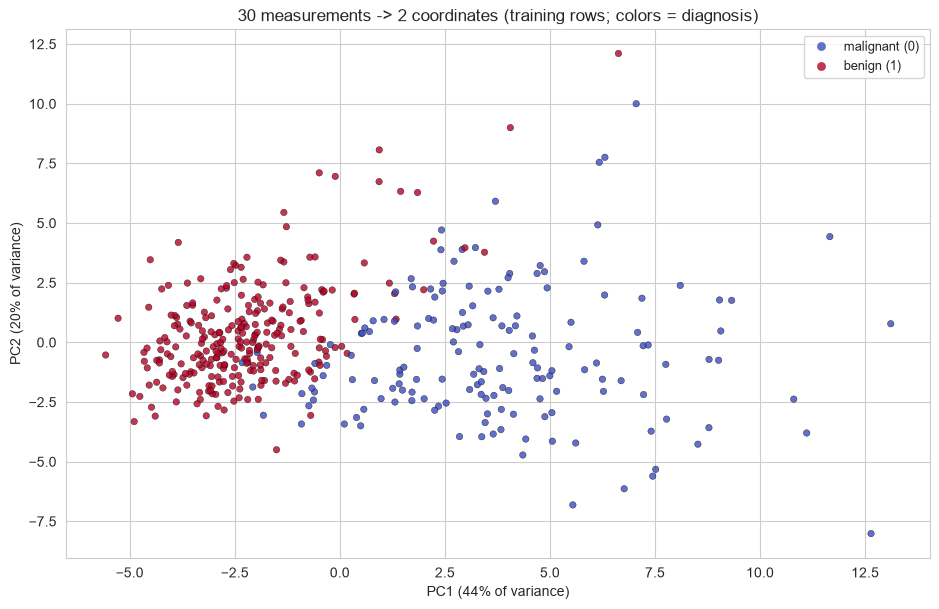


💡 Read the table, not the axis names: each PC is a WEIGHTED MIXTURE of 30 features, and the
   signed loadings say which measurements push a nucleus along the axis. The 2-D scatter is
   the same 30-D cloud, redrawn in two axes.


In [20]:
bc_ex = load_breast_cancer()
feat_names_ex = list(bc_ex.feature_names)
X_ex_tr, X_ex_te, y_ex_tr, y_ex_te = train_test_split(bc_ex.data, bc_ex.target, test_size=0.25,
                                                      stratify=bc_ex.target, random_state=42)
sc_ex = StandardScaler().fit(X_ex_tr)
X_ex_tr_s = sc_ex.transform(X_ex_tr)

pca_ex2 = PCA(n_components=2).fit(X_ex_tr_s)
Z_ex_tr = pca_ex2.transform(X_ex_tr_s)

print("=" * 60)
print("EXAMPLE 1: BREAST CANCER, 30 CORRELATED MEASUREMENTS")
print("=" * 60)
print(f"\n📊 variance captured by the first two components: "
      f"{pca_ex2.explained_variance_ratio_.sum():.1%} of the standardized spread")

top_ex = pd.DataFrame(pca_ex2.components_.T, columns=["PC1 loading", "PC2 loading"],
                      index=feat_names_ex)
biggest_abs = top_ex.abs().max(axis=1).sort_values(ascending=False).head(8).index
print(f"\n🔍 the eight most-loaded features across PC1/PC2 (loadings are mixtures over all 30):")
print(top_ex.loc[biggest_abs].round(3).to_string())

fig, ax = plt.subplots(figsize=(9.5, 6.2))
sc_plot = ax.scatter(Z_ex_tr[:, 0], Z_ex_tr[:, 1], c=y_ex_tr, cmap="coolwarm", s=22,
                     alpha=0.8, edgecolors="k", linewidths=0.3)
ax.set_xlabel(f"PC1 ({pca_ex2.explained_variance_ratio_[0]:.0%} of variance)")
ax.set_ylabel(f"PC2 ({pca_ex2.explained_variance_ratio_[1]:.0%} of variance)")
ax.set_title("30 measurements -> 2 coordinates (training rows; colors = diagnosis)")
ax.legend(handles=sc_plot.legend_elements()[0], labels=["malignant (0)", "benign (1)"], fontsize=9)
plt.tight_layout()
plt.show()

print("\n💡 Read the table, not the axis names: each PC is a WEIGHTED MIXTURE of 30 features, and the")
print("   signed loadings say which measurements push a nucleus along the axis. The 2-D scatter is")
print("   the same 30-D cloud, redrawn in two axes.")

In [21]:
# Compression vs accuracy: how far do 30 features travel before the classifier notices?
cum_ex = np.cumsum(PCA().fit(X_ex_tr_s).explained_variance_ratio_)
k_rule95 = int(np.searchsorted(cum_ex, 0.95) + 1)

pipe_rule95 = Pipeline([("sc", StandardScaler()), ("pca", PCA(n_components=k_rule95)),
                        ("clf", LogisticRegression(max_iter=5000))]).fit(X_ex_tr, y_ex_tr)
acc_rule95 = pipe_rule95.score(X_ex_te, y_ex_te)

# §7's CV-chosen k and its test score, reused (the search object exists from that cell)
acc_cv_k = search_bc.best_estimator_.score(Xb_te, yb_te)
pipe_no_pca = Pipeline([("sc", StandardScaler()), ("clf", LogisticRegression(max_iter=5000))]).fit(X_ex_tr,
                                                                                                      y_ex_tr)
acc_no_pca = pipe_no_pca.score(X_ex_te, y_ex_te)

rows_ex = pd.DataFrame(
    [
        ("all 30 features (rotation-free baseline)", 30, f"{cum_ex[-1]:.1%}", f"{acc_no_pca:.4f}"),
        ("95%-variance rule (k chosen from the spectrum)", k_rule95, f"{cum_ex[k_rule95 - 1]:.1%}",
         f"{acc_rule95:.4f}"),
        (f"§7's downstream-CV choice (k = {best_k_bc})", best_k_bc, f"{cum_ex[best_k_bc - 1]:.1%}",
         f"{acc_cv_k:.4f}"),
    ],
    columns=["design", "coords per row", "std variance kept", "test accuracy"],
)
print(rows_ex.to_string(index=False))
print("\n💡 Compression buys a fixed coordinate count for a stated variance share, and the downstream")
print("   score says what the share costs. When the rule-driven designs sit within a whisker of the")
print("   baseline, the 30-but-correlated features are telling their story through a handful of axes.")

                                        design  coords per row std variance kept test accuracy
      all 30 features (rotation-free baseline)              30            100.0%        0.9860
95%-variance rule (k chosen from the spectrum)              10             95.4%        0.9790
             §7's downstream-CV choice (k = 9)               9             94.2%        0.9790

💡 Compression buys a fixed coordinate count for a stated variance share, and the downstream
   score says what the share costs. When the rule-driven designs sit within a whisker of the
   baseline, the 30-but-correlated features are telling their story through a handful of axes.


### Example 2: Handwritten Digits — Map, Reconstruct, Denoise

The classic 1797 x 64 pixel set: every image is 8 x 8 pixel intensities 0–16, all in the same units. Three independent looks at one PCA: a 2-D map, a reconstruction gallery, and noise filtering.

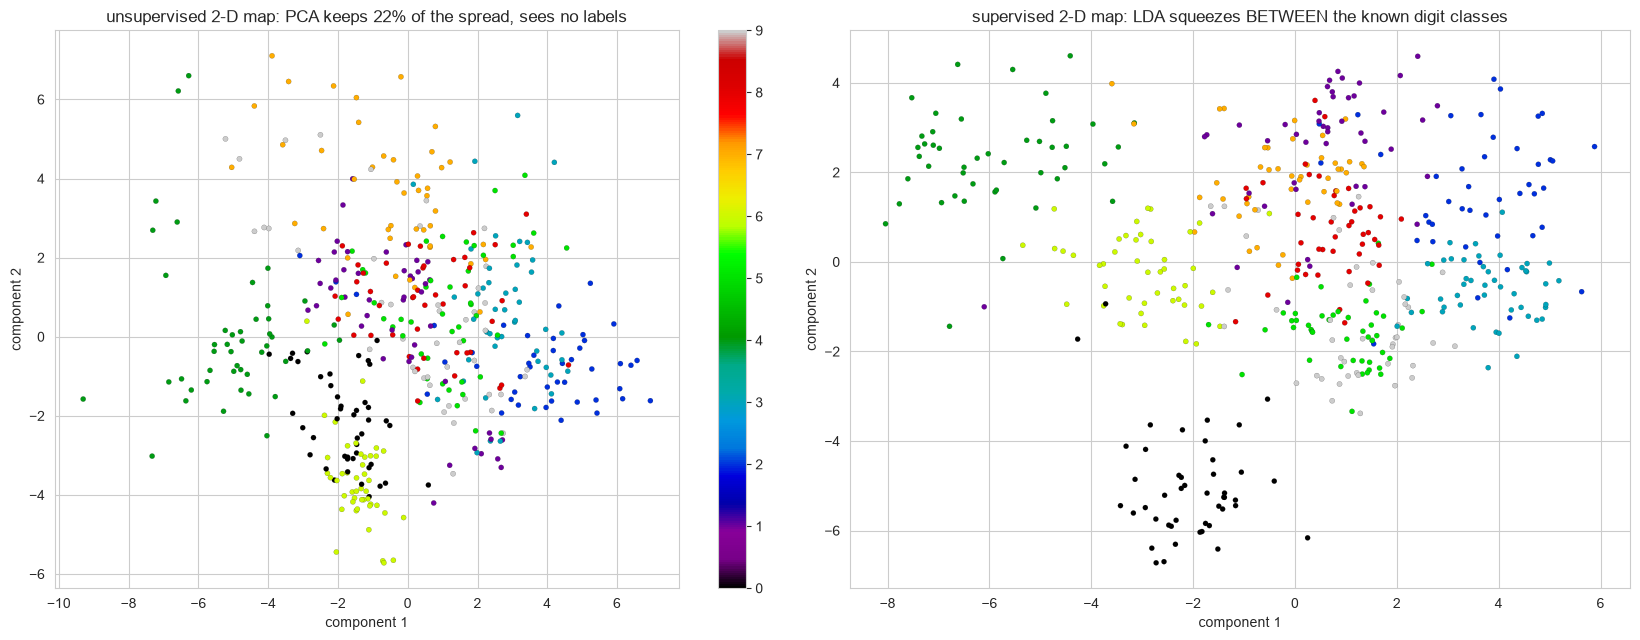


💡 Two 2-D maps of the same 64-D data: PCA unfolds the overall SPREAD (blurry class mush is a
   property of labels-blind variance), LDA unfolds the CLASS gaps — it may read y in the fit.
   That difference is §11's selection rule in picture form.


In [22]:
dig_ex = load_digits()
Xd_ex, yd_ex = dig_ex.data, dig_ex.target
Xd_tr_d, Xd_te_d, yd_tr_d, yd_te_d = train_test_split(Xd_ex, yd_ex, test_size=0.25,
                                                      stratify=yd_ex, random_state=42)
# pixels share units (0-16); standardizing is optional — we do it to let the two dead-border pixels
# whose variance is ~0 stop arguing with the informative ones
sc_d = StandardScaler().fit(Xd_tr_d)
Xd_tr_d_s, Xd_te_d_s = sc_d.transform(Xd_tr_d), sc_d.transform(Xd_te_d)

pca_d2_map = PCA(n_components=2).fit(Xd_tr_d_s)
Z_map = pca_d2_map.transform(Xd_te_d_s)

lda_d2 = LinearDiscriminantAnalysis(n_components=2).fit(Xd_tr_d_s, yd_tr_d)
Z_lda = lda_d2.transform(Xd_te_d_s)

fig, axes = plt.subplots(1, 2, figsize=(16.5, 6.5))
plot_map = axes[0].scatter(Z_map[:, 0], Z_map[:, 1], c=yd_te_d, cmap="nipy_spectral", s=14,
                           edgecolors="k", linewidths=0.1)
axes[0].set_title(f"unsupervised 2-D map: PCA keeps "
                  f"{pca_d2_map.explained_variance_ratio_.sum():.0%} of the spread, sees no labels")
axes[1].scatter(Z_lda[:, 0], Z_lda[:, 1], c=yd_te_d, cmap="nipy_spectral", s=14,
                edgecolors="k", linewidths=0.1)
axes[1].set_title("supervised 2-D map: LDA squeezes BETWEEN the known digit classes")
for ax_map in axes:
    ax_map.set_xlabel("component 1")
    ax_map.set_ylabel("component 2")
fig.colorbar(plot_map, ax=axes[0], ticks=range(10))
plt.tight_layout()
plt.show()

print("\n💡 Two 2-D maps of the same 64-D data: PCA unfolds the overall SPREAD (blurry class mush is a")
print("   property of labels-blind variance), LDA unfolds the CLASS gaps — it may read y in the fit.")
print("   That difference is §11's selection rule in picture form.")

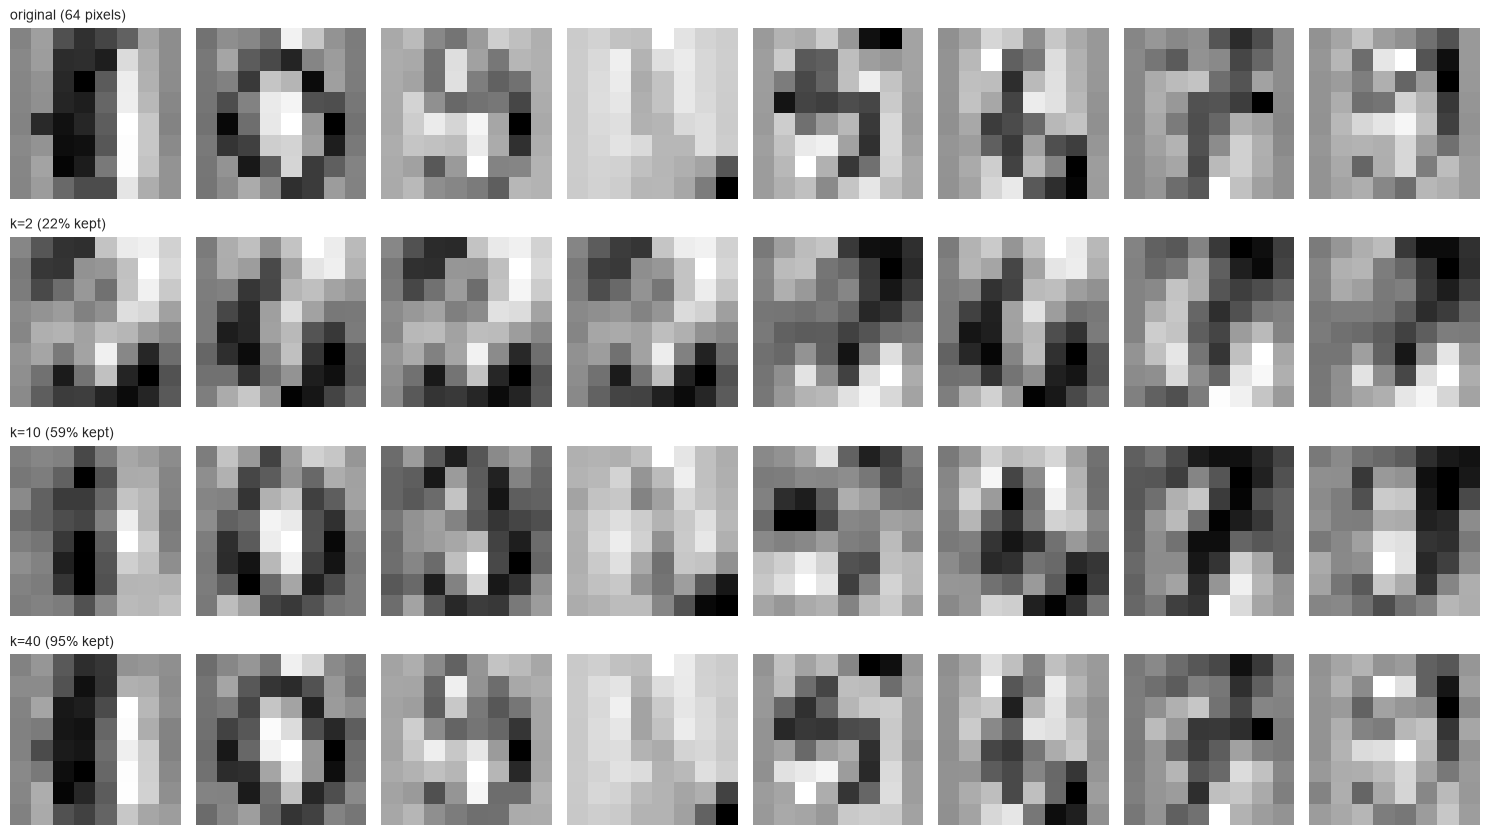

  k | variance kept | per-pixel MSE vs original
  2 |        21.6% |                    0.7680
 10 |        59.1% |                    0.3055
 40 |        95.3% |                    0.0405

💡 The gallery IS §5's truncation ladder, in pixels: k=2 sketches broad ink, k=40 is nearly
   original. And per the accountant, the MSE row could have been printed from the spectrum
   alone — reconstruction only exercises what the eigenvalues already knew.


In [23]:
# Reconstruction gallery: what each kept-prefix stores, rendered back into pixel space
pca_gallery = PCAScratch().fit(Xd_tr_d_s)                 # full spectrum, for the kept-share titles
levels_d = [2, 10, 40]
recons_d = []
for kk_gal in levels_d:
    model_gal = PCAScratch(n_components=kk_gal).fit(Xd_tr_d_s)
    recons_d.append(model_gal.inverse_transform(model_gal.transform(Xd_te_d_s[:8])))

fig, axes = plt.subplots(4, 8, figsize=(15, 8.6))
row_titles = [f"k={k} ({float(np.sum(pca_gallery.explained_variance_ratio_[:k])):.0%} kept)" for k in levels_d]
for img_col in range(8):
    axes[0][img_col].imshow(Xd_te_d_s[img_col].reshape(8, 8), cmap="gray_r")
    axes[0][img_col].axis("off")
    for row_k in range(len(levels_d)):
        axes[row_k + 1][img_col].imshow(recons_d[row_k][img_col].reshape(8, 8), cmap="gray_r")
        axes[row_k + 1][img_col].axis("off")
for row_k, title in enumerate(["original (64 pixels)"] + row_titles):
    axes[row_k][0].set_title(title, fontsize=10, loc="left")
plt.tight_layout()
plt.show()

print(f"{'k':>3s} | {'variance kept':>13s} | {'per-pixel MSE vs original':>25s}")
for idx_g, kk in enumerate(levels_d):
    mse_g = float(np.mean((Xd_te_d_s[:8] - recons_d[idx_g]) ** 2))
    print(f"{kk:3d} | {float(np.sum(pca_gallery.explained_variance_ratio_[:kk])):12.1%} | {mse_g:25.4f}")
print("\n💡 The gallery IS §5's truncation ladder, in pixels: k=2 sketches broad ink, k=40 is nearly")
print("   original. And per the accountant, the MSE row could have been printed from the spectrum")
print("   alone — reconstruction only exercises what the eigenvalues already knew.")

kept k = 10 of 64 components (52% of the
NOISY spectrum)  |  per-pixel MSE vs clean originals:
  noisy input  :    9.574
  after k=10 PCA filter:    8.040   (improvement factor 1.2x)


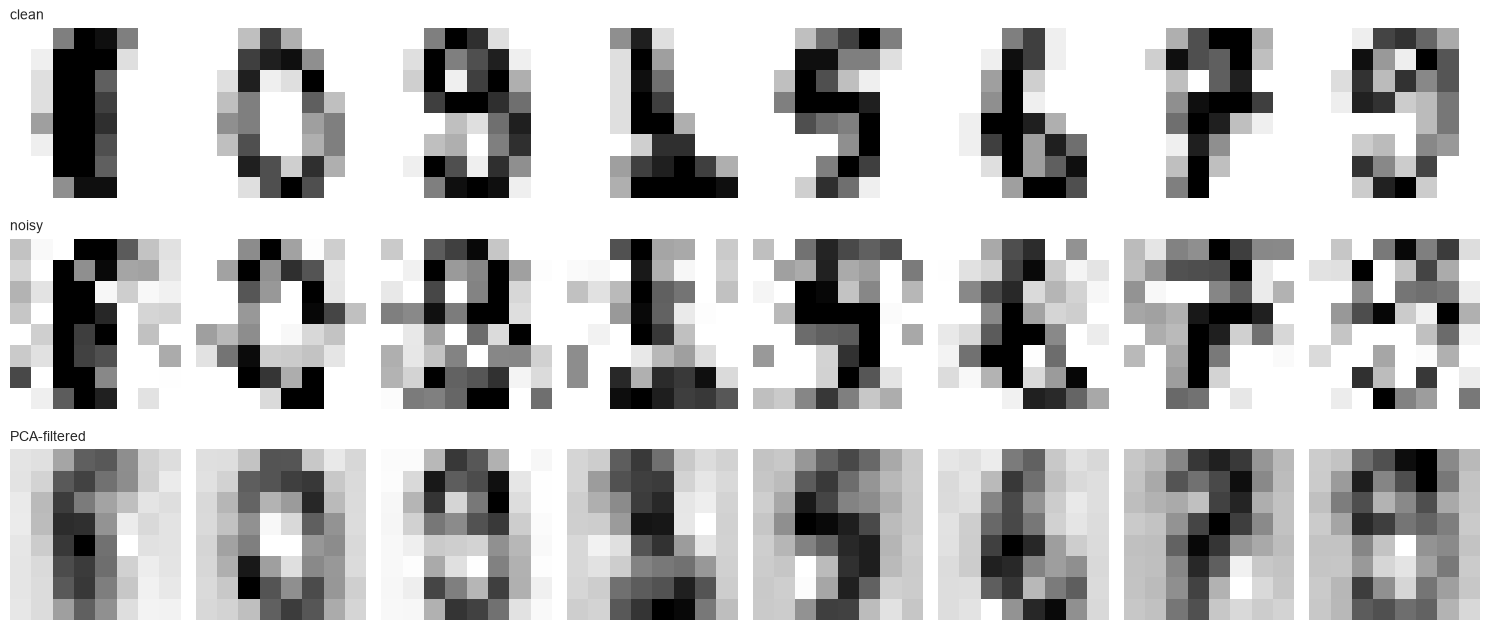


💡 Drop the small-eigenvalue tail and the SAND goes with it: a PCA filter keeps the broad
   ink directions and discards the per-pixel noise variance. Fit on the NOISY training data
   (labels untouched, no leakage) and transform the noisy test rows through that fit.


In [24]:
# Noise filtering: project the noisy images onto the leading components; the tail goes with the sand
rng_dn = np.random.default_rng(42)
Xd_noisy_tr = np.clip(Xd_tr_d + rng_dn.normal(0.0, 4.0, size=Xd_tr_d.shape), 0, 16)
Xd_noisy_te = np.clip(Xd_te_d + rng_dn.normal(0.0, 4.0, size=Xd_te_d.shape), 0, 16)

pca_dn_all = PCAScratch().fit(Xd_noisy_tr)
k_dn = int(np.searchsorted(np.cumsum(pca_dn_all.explained_variance_ratio_), 0.50) + 1)
pca_dn = PCAScratch(n_components=k_dn).fit(Xd_noisy_tr)
Xd_dn_te = pca_dn.inverse_transform(pca_dn.transform(Xd_noisy_te))

mse_noisy = float(np.mean((Xd_noisy_te - Xd_te_d) ** 2))
mse_dn = float(np.mean((Xd_dn_te - Xd_te_d) ** 2))
print(f"kept k = {k_dn} of 64 components ({float(np.sum(pca_dn.explained_variance_ratio_)):.0%} of the")
print(f"NOISY spectrum)  |  per-pixel MSE vs clean originals:")
print(f"  noisy input  : {mse_noisy:8.3f}")
print(f"  after k={k_dn} PCA filter: {mse_dn:8.3f}   (improvement factor {mse_noisy / mse_dn:.1f}x)")

fig, axes = plt.subplots(3, 8, figsize=(15, 6.6))
for img_m in range(8):
    axes[0][img_m].imshow(Xd_te_d[img_m].reshape(8, 8), cmap="gray_r")
    axes[0][img_m].set_title("clean" if img_m == 0 else "", fontsize=10, loc="left")
    axes[1][img_m].imshow(Xd_noisy_te[img_m].reshape(8, 8), cmap="gray_r")
    axes[1][img_m].set_title("noisy" if img_m == 0 else "", fontsize=10, loc="left")
    axes[2][img_m].imshow(Xd_dn_te[img_m].reshape(8, 8), cmap="gray_r")
    axes[2][img_m].set_title("PCA-filtered" if img_m == 0 else "", fontsize=10, loc="left")
for row_dn in axes.ravel():
    row_dn.axis("off")
plt.tight_layout()
plt.show()

print("\n💡 Drop the small-eigenvalue tail and the SAND goes with it: a PCA filter keeps the broad")
print("   ink directions and discards the per-pixel noise variance. Fit on the NOISY training data")
print("   (labels untouched, no leakage) and transform the noisy test rows through that fit.")

---

## 11. Comparison with Other Algorithms

### The Reduction Toolbox, Same Column of the Same Job

| Tool | Optimizes | Centering | Sparse input | Readable loadings | Learns `y` | Typical home |
|---|---|---|---|---|---|---|
| **PCA** | max projected variance (rotation) | ✅ | ⚠️ some solvers only ('arpack') | dense, signed | ❌ | compression/decorrelation of numeric blocks |
| **TruncatedSVD** | best rank-k WITHOUT centering | ❌ | ✅ | dense, signed | ❌ | TF-IDF/sparse matrices; explicit SVD needs |
| **KernelPCA** | variance in a kernel feature space | ✅ (kernel-dependent) | ❌ | not in raw features | ❌ | curved manifolds |
| **SparsePCA** | variance + ℓ1 sparsity | ✅ | ❌ | sparse (zeros) | ❌ | components that name their features |
| **IncrementalPCA** | PCA on streamed batches | ✅ | ❌ | dense | ❌ | huge n, memory bounds, `partial_fit` |
| **SelectKBest / f_classif** | univariate strength vs y | — | — | original features | ✅ | keep named, interpretable features |
| **LDA (projection)** | max class separation | — | — | dense | ✅ | supervised 2-D views; last-mile dims |
| **Autoencoders** | nonlinear reconstruction | — | — | — | ❌ | when PCA underfits and you can afford training (nn 17's family) |

t-SNE/UMAP are visualization-only (they do not transform unseen rows consistently) and outside this study repo's treatment — worth knowing they exist beyond the 2-D map uses above.

### When to Choose Plain PCA

- The features are numeric, correlated, and "variance ≈ relevance" is believable for the task
- You need a *labeling-blind* reducer (leakage-safe by construction) inside pipelines
- Determinism matters: no seeds, no iterations, every rerun identical
- A stated error budget must be honored — reconstruction error is known before slicing

### The Counterexample in Numbers

Same 8 features, standardized throughout. Six of them are a correlated noise block; two are nearly independent but carry the class. What each reducer hands the classifier (5-fold CV, logistic regression):

In [25]:
# The dataset: two 3-feature correlated noise sub-blocks (var-dominant), 2 narrow predictive dims
n_sig = 400
rng_sig = np.random.default_rng(42)
cov_noise_sig = np.zeros((6, 6))
cov_noise_sig[:3, :3] = 0.6                       # block A: correlated among its 3 features
cov_noise_sig[3:, 3:] = 0.6                       # block B: correlated among its own 3
np.fill_diagonal(cov_noise_sig, 1.0)
noise_block_sig = rng_sig.multivariate_normal(np.zeros(6), cov_noise_sig, size=n_sig)
y_sig = rng_sig.integers(0, 2, size=n_sig)
s1_sig = rng_sig.normal(0.0, 0.5, size=n_sig) + np.where(y_sig == 1, 1.0, -1.0)
s2_sig = rng_sig.normal(0.0, 0.5, size=n_sig) + np.where(y_sig == 1, -0.8, 0.8)
X_sig = np.hstack([noise_block_sig, np.column_stack([s1_sig, s2_sig])])

# the standardized spectrum: WHERE the signal eigenvalues actually sit
eig_sig = PCAScratch().fit(StandardScaler().fit_transform(X_sig)).explained_variance_
print("standardized eigenvalues (descending):", np.round(eig_sig, 2))
print("-> the top 2 eigenvalues (both ~ 1 + 2 x 0.6) are the noise blocks' shared axes;")
print("   the two signal dims sit mid-spectrum at ~1.0 -- variance-blind ranking cannot tell them apart\n")

rows_sig = []
cv_sig = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
reducers_sig = {
    "PCA, k=2 (the reflex)": Pipeline([("sc", StandardScaler()), ("red", PCA(n_components=2)),
                                       ("clf", LogisticRegression(max_iter=5000))]),
    "SelectKBest, k=2": Pipeline([("sc", StandardScaler()),
                                  ("red", SelectKBest(f_classif, k=2)),
                                  ("clf", LogisticRegression(max_iter=5000))]),
    "all 8 features": Pipeline([("sc", StandardScaler()),
                                ("clf", LogisticRegression(max_iter=5000))]),
}
for name_sig, est_sig in reducers_sig.items():
    scores_sig = cross_val_score(est_sig, X_sig, y_sig, cv=cv_sig, scoring="accuracy", n_jobs=-1)
    rows_sig.append({"reducer": name_sig, "CV accuracy": scores_sig.mean(), "± std": scores_sig.std()})

sig_df = pd.DataFrame(rows_sig)
print(sig_df.to_string(index=False, float_format=lambda v: f"{v:.4f}"))
print("\n💡 The k=2 reflex hands the classifier the two LOUDEST axes — both pure noise here — while")
print("   SelectKBest reads the score against y and keeps the two quiet-but-predictive features.")
print("   §7's CV-searched k would escape (k = 3..5 admits the lambda~1 dims) -- but no k makes PCA")
print("   a feature selector: the signal stays mixed across axes, and named features never survive.")

standardized eigenvalues (descending): [2.33 2.17 1.73 0.45 0.4  0.35 0.35 0.24]
-> the top 2 eigenvalues (both ~ 1 + 2 x 0.6) are the noise blocks' shared axes;
   the two signal dims sit mid-spectrum at ~1.0 -- variance-blind ranking cannot tell them apart

              reducer  CV accuracy  ± std
PCA, k=2 (the reflex)       0.5850 0.0289
     SelectKBest, k=2       0.9925 0.0061
       all 8 features       0.9925 0.0061

💡 The k=2 reflex hands the classifier the two LOUDEST axes — both pure noise here — while
   SelectKBest reads the score against y and keeps the two quiet-but-predictive features.
   §7's CV-searched k would escape (k = 3..5 admits the lambda~1 dims) -- but no k makes PCA
   a feature selector: the signal stays mixed across axes, and named features never survive.


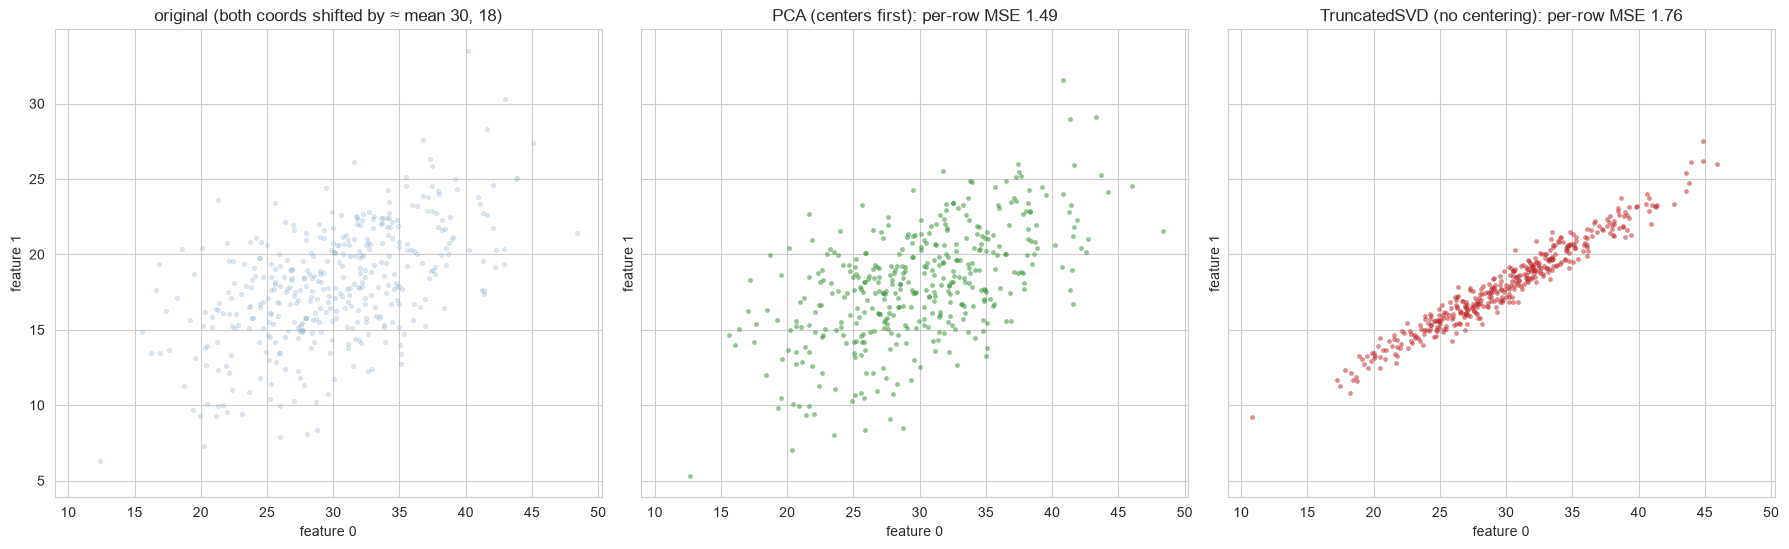

rank-2 reconstruction MSE: PCA 1.49  vs  TruncatedSVD 1.76  (1x worse)

💡 Same SVD machinery; the difference is the mean. PCA factors the mean OUT first, so its
   2 components describe spread; an uncentered SVD spends them describing WHERE the cloud
   sits. That's why text/sparse pipelines (which often skip centering) reach for TruncatedSVD —
   and why centering is the first line inside the twin's fit.


In [26]:
# The hidden half of PCA: centering, demonstrated where it matters
shift8 = np.array([30.0, 18.0, 9.0, 5.0, 3.0, 2.0, 1.5, 1.0])   # a sizeable mean, same feature units
X8_shift = X8 + shift8

pca_shift = PCA(n_components=2)              # centers internally
svd_shift = TruncatedSVD(n_components=2, random_state=0)   # factorizes the RAW matrix, mean included
recon_pc = pca_shift.inverse_transform(pca_shift.fit_transform(X8_shift))
recon_sv = svd_shift.inverse_transform(svd_shift.fit_transform(X8_shift))

mse_pc = float(np.mean((X8_shift - recon_pc) ** 2))
mse_sv = float(np.mean((X8_shift - recon_sv) ** 2))

fig, axes = plt.subplots(1, 3, figsize=(18, 5.6), sharex=True, sharey=True)
axes[0].scatter(X8_shift[:, 0], X8_shift[:, 1], s=10, alpha=0.4, color="#9ec5e8",
                edgecolors="k", linewidths=0.1)
axes[0].set_title(f"original (both coords shifted by ≈ mean {shift8[0]:.0f}, {shift8[1]:.0f})")
axes[1].scatter(recon_pc[:, 0], recon_pc[:, 1], s=10, alpha=0.55, color="#2ca02c",
                edgecolors="k", linewidths=0.1)
axes[1].set_title(f"PCA (centers first): per-row MSE {mse_pc:.2f}")
axes[2].scatter(recon_sv[:, 0], recon_sv[:, 1], s=10, alpha=0.55, color="#d62728",
                edgecolors="k", linewidths=0.1)
axes[2].set_title(f"TruncatedSVD (no centering): per-row MSE {mse_sv:.2f}")
for ax_sv in axes:
    ax_sv.set_xlabel("feature 0")
    ax_sv.set_ylabel("feature 1")
plt.tight_layout()
plt.show()

print(f"rank-2 reconstruction MSE: PCA {mse_pc:.2f}  vs  TruncatedSVD {mse_sv:.2f}  "
      f"({mse_sv / mse_pc:.0f}x worse)")
print("\n💡 Same SVD machinery; the difference is the mean. PCA factors the mean OUT first, so its")
print("   2 components describe spread; an uncentered SVD spends them describing WHERE the cloud")
print("   sits. That's why text/sparse pipelines (which often skip centering) reach for TruncatedSVD —")
print("   and why centering is the first line inside the twin's fit.")

---

## 12. References

### 📚 Academic Papers & Books

1. **Original Work**:
   - **Pearson, K. (1901). "On Lines and Planes of Closest Fit to Systems of Points in Space."** *Philosophical Magazine*, 2(11): the least-squares best-fit subspace view
   - **Hotelling, H. (1933). "Analysis of a Complex of Statistical Variables into Principal Components."** *Journal of Educational Psychology*, 24(6–7): the variance-maximization view and the name
2. **The Probabilistic Model**:
   - **Tipping, M. E., & Bishop, C. M. (1999). "Probabilistic Principal Component Analysis."** *JRSS-B*, 61(3): the model behind `score`, `score_samples`, `noise_variance_`, and closed-form PPCA
3. **Algorithmic Extensions**:
   - **Minka, T. P. (2001). "Automatic Choice of Dimensionality for PCA."** *NIPS 2000*: the `'mle'` dimensionality rule
   - **Halko, N., Martinsson, P. G., & Tropp, J. A. (2011). "Finding Structure with Randomness."** *SIAM Review*, 53(2): the randomized SVD behind `svd_solver='randomized'`
   - Ross, D., Lim, J., Lin, R.-S., & Yang, M.-H. (2008). "Incremental Learning for Robust Visual Tracking." *IJCV*, 30(2): incremental eigenbasis updating — the idea behind `IncrementalPCA`
   - Wold, H., Esbensen, K., & Geladi, P. (1987). "Principal Component Analysis." *Chemometrics and Intelligent Laboratory Systems*, 2(1–3): the practical NIPALS/streaming-road tour
4. **Textbooks**:
   - **Jolliffe, I. T. (2002). *Principal Component Analysis*, 2nd ed.** Springer: the standard monograph
   - Hastie, T., Tibshirani, R., & Friedman, J. (2009). *The Elements of Statistical Learning*, §14.5 (free PDF at hastie.su.domains)
   - James, G., et al. (2013). *An Introduction to Statistical Learning*, §12.2 (free PDF at statlearning.com)
   - Bishop, C. M. (2006). *Pattern Recognition and Machine Learning*, §12.1

### 🌐 Online Resources

- [Scikit-learn PCA API reference](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html) — parameter/attribute ground truth for §8 (documented here against sklearn 1.9, the repo's pin)
- [Scikit-learn decomposition user guide](https://scikit-learn.org/stable/modules/decomposition.html#principal-component-analysis-pca)
- [Unsupervised dimensionality reduction](https://scikit-learn.org/stable/modules/unsupervised_reduction.html) — the family tour behind §6's variants
- StatQuest's PCA videos (search "StatQuest PCA step-by-step"): the friendliest spectral walkthrough
- The eigenfaces classic: Turk & Pentland (1991), *Journal of Cognitive Neuroscience* — a fun read AFTER this notebook

### 📊 Key Concepts to Master

- **The eigenproblem**: $\Sigma v = \lambda v$ — components are covariance eigenvectors; λ_i is the variance along each
- **Ratios vs kept**: `explained_variance_ratio_` shares the trace of the FULL covariance; only the all-components fit sums to 1.0
- **SVD bridge**: components_ = $V^\top$, singular values = coordinate norms, λ = s²/(n−1)
- **Truncation is honest**: reconstruction error = the dropped-eigenvalue sum (Eckart–Young), known before fitting
- **Units rule the spectrum**: comparable features → raw fit; mismatched units → standardize in-pipeline
- **Variance ≠ signal**: the labeling-blind reducer's safety (no y leakage) is also its failure mode (§11)
- **k is a decision, not a knob**: choose it by downstream CV (serving models) or an explicit budget (compression)

### 🔗 Related Notebooks and Repository Files

- `12_clustering_kmeans.ipynb` and `13_clustering_hierarchical.ipynb`: the row-partition siblings — notebook 12 even takes a quick 2-component PCA peek of its data
- `17_neural_networks_basics.ipynb`: nonlinear compression's price (autoencoders earn their keep against THIS baseline)
- `src/models/dimensionality_reduction.py`: the from-scratch twin used in §5
- `tests/models/test_dimensionality_reduction.py`: the behaviors pinned down (sklearn agreement at 1e-8, sign handling, clamping, validation)
- `app/registry/algorithms/pca.py`: the app card — same dataset (`pca_correlated_4f`), same cumulative-variance lesson, one `n_components` slider
- `other/hyperparameter_guide.md` and `other/when_to_use_what.md`: family-level tuning and selection context

## Summary & Key Takeaways

### What We Learned

1. **Theory**: PCA factorizes the covariance ($\Sigma v = \lambda v$); components are eigenvectors, λ_i is the variance along each, and ratios are shares of the total trace
2. **SVD bridge**: sklearn factorizes the centered data ($X_c = U S V^\top$) — same axes, and the twin's covariance-eigh road reaches them to float precision for n ≥ 2
3. **Truncation**: keeping k components costs exactly the dropped eigenvalues (Eckart–Young) — an error budget you can print before fitting; keeping the full rank is a pure, lossless rotation
4. **Assumptions**: linear structure, variance-as-importance, comparable units, tolerance for outliers; violations have table-mapped symptoms (§3)
5. **Implementation**: the twin = center → ddof=1 covariance → eigh → descending → clamp → sign-fix; seven lines you can re-derive (§5 hand-check)
6. **Scikit-learn**: the parameter set (§8) beyond the twin — `whiten`, five solvers, `'mle'`/share-k forms — all documented against sklearn 1.9
7. **Choosing k**: spectrum rules (cumulative/elbow/Kaiser) for viewing, downstream CV for serving, reconstruction budget for rendering
8. **Practice**: breast cancer (interpret loadings, compress with a stated share), digits (2-D map, reconstruction gallery, noise filtering), and the §11 counterexample separating variance from prediction

### When to Use PCA

✅ **Use when**:
- features are numeric, correlated, and their variance is meaningful information
- downstream models need decorrelated, lower-dimensional inputs
- you need a deterministic, seedless, error-bounded reducer inside pipelines
- you must view high-dimensional data honestly in 2–3 components

❌ **Avoid when**:
- named-feature interpretability is the product (selection/regularized models instead)
- variance does not track the label (SelectKBest/LDA; §11)
- strong nonlinear structure dominates (KernelPCA; visualization-only t-SNE/UMAP)
- the matrix is sparse or streaming (TruncatedSVD / IncrementalPCA)

### Best Practices Checklist

- ✅ standardize when units disagree — inside the Pipeline, fitted on training rows
- ✅ never let the scaler/PCA statistics see evaluation rows (§9's leak demo)
- ✅ choose k by an explicit rule; CV when PCA serves a model
- ✅ audit every fit: orthonormal axes, `mean_` check, ratios-sum sanity, exact full-rank reconstruction
- ✅ read loadings with the sign convention in mind; compare engines with alignment, not `==`
- ✅ use the right solver/variant for the job (§8 recipes, §11 toolbox)

### Critical Requirements

1. **Numeric, complete, finite features** — impute before the pipeline
2. **A scale decision** — standardize (correlation-PCA) or declare the raw units meaningful
3. **Enough rows** — a spectrum from 20 rows over 200 features is noise-reading
4. **A stated k rule** — the only hyperparameter that changes the information budget

### Advantages vs Disadvantages

**Advantages:**
- ✅ exact, deterministic, seedless; microseconds-to-instant at study scale
- ✅ unbeatable decorrelation: outputs are mutually uncorrelated by construction
- ✅ error accounting built in: dropped eigenvalues IS the compression cost
- ✅ labeling-blind: pipeline-safe preprocessing (no y leakage by design)

**Disadvantages:**
- ❌ components are mixtures — original feature semantics are lost
- ❌ variance-ordered, not target-tuned: signal can fall off the kept prefix (§11)
- ❌ linear by construction: curved manifolds slide past straight planes
- ❌ sensitive to units and outliers (§2's x1000 trap, §3's pivoting axis)
- ❌ full covariance costs O(d²) memory — huge sparse/streaming needs other tools

### Unique Characteristic: The Error You Can See Coming

Every other reducer in this repo learns its cost by flying. PCA's compression cost is a sum in a table — the eigenvalues it will drop — *before* any fitting, any CV, any seed. Rotation keeps everything; truncation costs exactly the smallest eigenvalues; that transparent ledger is why PCA remains the default first tool of dimensionality reduction.

### Next Steps

1. **Practice** on your own data: `Pipeline(StandardScaler → PCA(k by CV) → model)` where PCA serves a model, and a scree + budget where PCA is the point
2. **Diagnose**: read the loadings of PC1 with feature names, check the kept-prefix share against the target you set, verify the full-rank exactness once per dataset
3. **Compare** the §11 toolbox on one real dataset — PCA vs TruncatedSVD vs SelectKBest vs LDA — and let the downstream CV write the verdict
4. **Run the app card** (`app/registry/algorithms/pca.py`): drag the `n_components` slider on `pca_correlated_4f` — the bars never move, the red marker cuts the same cumulative line §7's spectrum cells build
5. **Read** `tests/models/test_dimensionality_reduction.py` to see the twin's pinned conventions, then continue the notebooks: 14 (DBSCAN), 16 (ensemble methods), 17 (neural nets)

---

**Congratulations!** You can now build the whole eigen-argument from scratch, read a fitted spectrum, predict compression error before transforming, and know exactly when variance-based reduction is the wrong currency. 🎯🎉

**Remember**: PCA is a rotation first and a compression second. Scale your units, keep the k your downstream score (or budget) picks, and never let test rows touch the fit — the spectrum will tell you the rest.